> Historical saved outputs are preserved below. Embedded WAV playback outputs were omitted from this public copy; the complete recovered notebook remains in the local BTP directory.

# A few Improvements and changes to data

## setup, and a safe decision-log helper

In [ ]:
print("=" * 100)
print("CELL N0 - SETUP: imports, folders and a SAFE decision-log helper")
print("=" * 100)
from pathlib import Path
import io, csv, json, re, datetime, collections
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import soundfile as sf
from IPython.display import display

pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)

import os
ROOT = Path(os.environ.get("BTP_ROOT", Path.cwd())).resolve()
RAW_A = ROOT / "raw" / "A_narration" / "data"                     # the untouched raw Narration data
MAN = ROOT / "manifests"; CLEAN = ROOT / "cleaning"; META = ROOT / "metadata"
for d in (MAN, CLEAN, META):
    d.mkdir(exist_ok=True)                                         # create the folder if it is missing

TODAY = datetime.date.today().isoformat()
LOG = CLEAN / "decision_log_A.csv"                                 # the plan keeps the decision log in cleaning/
LOG_COLS = ["date", "step", "decision", "reason", "rows_affected", "hours_affected"]

def log_decision(step, decision, reason, rows=None, hours=None):
    """Append ONE decision to the log, but only if a decision with exactly this text is not already there.
    Running a cell twice therefore never creates duplicates, and no earlier entry is ever deleted or overwritten."""
    known = set(pd.read_csv(LOG, encoding="utf-8-sig")["decision"]) if LOG.exists() else set()
    if decision in known:
        print("   (already logged)", decision[:80]); return
    new_file = not LOG.exists()
    with open(LOG, "a", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        if new_file: w.writerow(LOG_COLS)
        w.writerow([TODAY, step, decision, reason, rows, hours])
    print("   logged:", decision[:80])

# One-time move of the old log (manifests/) into cleaning/, dropping the duplicate entry that Cell L6 created when it ran twice.
OLD_LOG = MAN / "decision_log_A.csv"
if not LOG.exists() and OLD_LOG.exists():
    old = pd.read_csv(OLD_LOG, encoding="utf-8-sig").drop_duplicates(subset="decision", keep="first")
    old.to_csv(LOG, index=False, encoding="utf-8-sig")
    print(f"Moved the old log to {LOG} ({len(old)} entries; duplicates removed). The old file in manifests/ was left untouched - you can delete it.")
else:
    print("Decision log:", LOG, "| exists:", LOG.exists())
print("\nSetup done. Folders:", MAN.name, CLEAN.name, META.name)

## load master v1 and the raw columns that were left out

In [13]:
print("=" * 100)
print("CELL N1 - LOAD master_A (version 1) AND THE RAW COLUMNS THAT WERE LEFT OUT")
print("=" * 100)
M1 = pd.read_parquet(MAN / "master_A.parquet")                     # version 1: we never overwrite it, we build version 1.1 next to it
assert len(M1) == 6718, "unexpected number of rows"
print(f"master_A (v1): {M1.shape[0]} rows x {M1.shape[1]} columns")
print("speaker_status counts (expected ok 5712, linked_to_pair 622, multi_person 208, uncertain_identity 176):")
print(M1["speaker_status"].value_counts().to_string())

# Every row says where its raw data is: "raw/A_narration/data/<split>/<file>#row=<n>". Split that into three keys.
keys = M1["audio_path"].str.extract(r"data/(?P<split>\w+)/(?P<file>[^#]+)#row=(?P<row_in_file>\d+)")
keys["row_in_file"] = keys["row_in_file"].astype(int)

# Re-read the raw table (everything except the audio bytes) so we can attach the columns that master v1 dropped.
parts = []
for f in sorted(RAW_A.glob("*/*.parquet")):
    t = pq.read_table(f, columns=[c for c in pq.ParquetFile(f).schema_arrow.names if c != "audio"]).to_pandas()
    t["split"] = f.parent.name; t["file"] = f.name; t["row_in_file"] = range(len(t))
    parts.append(t)
RAW = pd.concat(parts, ignore_index=True)
R = keys.merge(RAW, on=["split", "file", "row_in_file"], how="left")      # one raw row for every master row, same order as M1
assert len(R) == len(M1) and R["audio_id"].notna().all(), "some master rows could not be found in the raw data"
assert (R["audio_id"].values == M1["original_audio_id"].values).all(), "raw rows are not aligned with the master rows"
print(f"\nAll {len(R)} master rows were matched to their raw row and the audio IDs agree.")

CELL N1 - LOAD master_A (version 1) AND THE RAW COLUMNS THAT WERE LEFT OUT
master_A (v1): 6718 rows x 39 columns
speaker_status counts (expected ok 5712, linked_to_pair 622, multi_person 208, uncertain_identity 176):
speaker_status
ok                    5712
linked_to_pair         622
multi_person           208
uncertain_identity     176

All 6718 master rows were matched to their raw row and the audio IDs agree.


In [14]:
print("=" * 100)
print("CELL N2 - SPEAKER GROUPS: find one person who appears under several speaker IDs")
print("=" * 100)
print("""WHY: the same person can be recorded in two campaigns and receive two different public IDs. If we later split by speaker ID,
that person could end up in train AND test. A new column speaker_group_id merges the IDs that very probably belong to one person.
The column speaker_id itself is NOT changed.
RULE A (automatic): public IDs whose raw speakerId has the same NAME STEM (name without the age code and timestamp) are one person.
RULE B (manual)   : name stems that you judge to be spelling variants of one name. Edit the list below if you disagree.
""")
MANUAL_STEM_MERGES = [("likhaaku", "likkaaku")]     # both Female 18-30; names differ by one letter. Delete this entry if you think they are different people.

solo = M1[~M1["is_pair_recording"]].copy()                                       # pair recordings have two names in the ID, so they have no single stem
solo["stem"] = solo["speaker_id_raw"].str.replace(r"\d+(_\d+)?$", "", regex=True)  # "tajjarbo3045_22561" -> "tajjarbo"
ids_by_stem = solo.groupby("stem")["speaker_id"].unique()

parent = {p: p for p in M1["speaker_id"].unique()}                                 # union-find: every public ID starts as its own group
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b): parent[find(a)] = find(b)

reason = {}
for stem, ids in ids_by_stem.items():                                              # RULE A
    for other in ids[1:]:
        union(ids[0], other)
        reason[stem] = "same name stem under more than one public ID"
for a, b in MANUAL_STEM_MERGES:                                                    # RULE B
    ids = list(ids_by_stem.get(a, [])) + list(ids_by_stem.get(b, []))
    for other in ids[1:]:
        union(ids[0], other)
    reason[a + "~" + b] = "manual: look-alike names (possible spelling variants)"

members = collections.defaultdict(list)
for p in parent: members[find(p)].append(p)
stems_of = solo.groupby("speaker_id")["stem"].apply(lambda s: sorted(set(s))).to_dict()
group_name = {}
for root, ids in members.items():
    if len(ids) == 1:
        group_name[ids[0]] = ids[0]                                                # not merged: the group is just the public ID
    else:
        name = "SG_" + "_".join(sorted({s for i in ids for s in stems_of.get(i, [])}))
        for i in ids: group_name[i] = name

M1["speaker_group_id"] = M1["speaker_id"].map(group_name)
M1["group_train_only"] = M1.groupby("speaker_group_id")["train_only"].transform("max")   # if ANY member is train-only, the whole group is

def label_of(s):
    u = sorted(s.dropna().unique())
    return "unknown" if len(u) == 0 else "/".join(u)
M1["recording_month"] = pd.to_datetime(M1["recording_session_id"].str[1:9], format="%Y%m%d", errors="coerce").dt.to_period("M").astype(str)

merged = M1[M1["speaker_group_id"] != M1["speaker_id"]]
G = merged.groupby("speaker_group_id").agg(
    public_ids=("speaker_id", "nunique"), clips=("sample_id", "size"), hours=("duration_seconds", lambda x: round(x.sum() / 3600, 3)),
    gender=("gender", label_of), age=("age_group", label_of), months=("recording_month", lambda x: ",".join(sorted(set(x)))),
    status=("speaker_status", lambda x: "/".join(sorted(set(x)))))
print(f"Public speaker IDs: {M1['speaker_id'].nunique()}  ->  speaker groups: {M1['speaker_group_id'].nunique()}  (expected 60 -> 55)")
print("\nGroups that were merged (check gender/age: a group with two different genders is only expected for the unresolved pair recordings):")
display(G)
ok_groups = M1[~M1["group_train_only"]]["speaker_group_id"].nunique()
print(f"\nGroups that may go to validation/test (no train-only member): {ok_groups}   (before grouping: {M1[~M1['train_only']]['speaker_id'].nunique()} speaker IDs)")

CELL N2 - SPEAKER GROUPS: find one person who appears under several speaker IDs
WHY: the same person can be recorded in two campaigns and receive two different public IDs. If we later split by speaker ID,
that person could end up in train AND test. A new column speaker_group_id merges the IDs that very probably belong to one person.
The column speaker_id itself is NOT changed.
RULE A (automatic): public IDs whose raw speakerId has the same NAME STEM (name without the age code and timestamp) are one person.
RULE B (manual)   : name stems that you judge to be spelling variants of one name. Edit the list below if you disagree.

Public speaker IDs: 60  ->  speaker groups: 55  (expected 60 -> 55)

Groups that were merged (check gender/age: a group with two different genders is only expected for the unresolved pair recordings):


,public_ids,clips,hours,gender,age,months,status
speaker_group_id,,,,,,,
SG_joramjyoti_joramyano,2,103,0.287,Female/Male,45-60,2024-11,uncertain_identity
SG_likhaaku_likkaaku,2,403,1.173,Female,18-30,"2024-11,2025-04,2025-06,2025-07,2025-08",ok
SG_pachurinya_totosuka,2,73,0.229,Female,30-45/45-60,2024-11,uncertain_identity
SG_pelkamin,2,62,0.221,Male,30-45,2024-11,ok
SG_tajjarbo,2,307,0.792,Male,30-45,"2024-11,2025-04,2025-06",ok



Groups that may go to validation/test (no train-only member): 46   (before grouping: 49 speaker IDs)


In [15]:
print("=" * 100)
print("CELL N3 - DECODE EVERY CLIP AND STORE THE FACTS (format, real length) - takes about 30 seconds the first time")
print("=" * 100)
FACTS = MAN / "audio_facts_A.parquet"
if FACTS.exists():
    AF = pd.read_parquet(FACTS); print("Found a saved result, loaded it:", FACTS.name)
else:
    lookup = dict(zip(zip(keys["split"], keys["file"], keys["row_in_file"]), M1["sample_id"]))
    rec = []
    for f in sorted(RAW_A.glob("*/*.parquet")):
        pf = pq.ParquetFile(f); base = 0
        for g in range(pf.num_row_groups):
            for i, a in enumerate(pf.read_row_group(g, columns=["audio"]).column("audio").to_pylist()):
                try:
                    info = sf.info(io.BytesIO(a["bytes"]))                       # reads only the WAV header: format, rate, channels, length
                    rec.append(dict(sample_id=lookup[(f.parent.name, f.name, base + i)], decodes=True, audio_subtype=info.subtype,
                                    audio_sr=info.samplerate, audio_channels=info.channels, n_frames=info.frames, duration_decoded=round(info.duration, 3)))
                except Exception as e:
                    rec.append(dict(sample_id=lookup[(f.parent.name, f.name, base + i)], decodes=False, audio_subtype=None,
                                    audio_sr=None, audio_channels=None, n_frames=0, duration_decoded=0.0))
            base += pf.metadata.row_group(g).num_rows
    AF = pd.DataFrame(rec); AF.to_parquet(FACTS, index=False); print("Saved:", FACTS)

AF = M1[["sample_id", "duration_seconds"]].merge(AF, on="sample_id", how="left")
AF["format_ok"] = AF["decodes"] & (AF["audio_sr"] == 16000) & (AF["audio_channels"] == 1) & (AF["audio_subtype"] == "PCM_16")
AF["length_matches_stated"] = (AF["duration_decoded"] - AF["duration_seconds"]).abs() <= 0.05
AF["audio_issue"] = np.where(~AF["decodes"], "does_not_decode", np.where(AF["n_frames"] == 0, "empty_audio",
                    np.where(~AF["format_ok"], "unexpected_format", np.where(~AF["length_matches_stated"], "length_differs_from_stated", ""))))
AF["audio_ok"] = AF["audio_issue"] == ""
print("\nAudio format of all clips (expected: one row, 6718 clips, 16000 Hz, 1 channel, PCM_16):")
display(AF.groupby(["audio_subtype", "audio_sr", "audio_channels"]).size().rename("clips").reset_index())
print("Clips with an audio problem (expected 4: A_004972 truncated, A_004973 / A_006614 / A_006615 empty):")
display(AF[~AF["audio_ok"]][["sample_id", "duration_seconds", "duration_decoded", "audio_issue"]])

CELL N3 - DECODE EVERY CLIP AND STORE THE FACTS (format, real length) - takes about 30 seconds the first time
Saved: C:\Users\Kanchan Potdar\Downloads\BTP\manifests\audio_facts_A.parquet

Audio format of all clips (expected: one row, 6718 clips, 16000 Hz, 1 channel, PCM_16):


,audio_subtype,audio_sr,audio_channels,clips
0,PCM_16,16000,1,6718


Clips with an audio problem (expected 4: A_004972 truncated, A_004973 / A_006614 / A_006615 empty):


,sample_id,duration_seconds,duration_decoded,audio_issue
4971,A_004972,3.89,2.531,length_differs_from_stated
4972,A_004973,0.82,0.000,empty_audio
6613,A_006614,10.97,0.000,empty_audio
6614,A_006615,10.92,0.000,empty_audio


In [16]:
print("=" * 100)
print("CELL N4 - BUILD master_A version 1.1 (version 1 stays untouched)")
print("=" * 100)
M2 = M1.copy()

# (1) the five original columns that version 1 dropped; the literal text 'N/A' becomes a real empty value
def clean(s): return s.where(~s.astype(str).str.strip().isin(["N/A", "", "nan", "None"]), None)
M2["education_medium_after_12"] = clean(R["speaker1-educationMediumAfter12-list"]).values
M2["education_medium_upto_12"] = clean(R["speaker1-educationMediumUpto12-list"]).values
M2["life_speaker_id"] = clean(R["speaker1-lifespeakerid"]).values
M2["speaker2_place_of_recording"] = clean(R["speaker2-placeOfRecording"]).values
M2["speaker2_type_of_place"] = clean(R["speaker2-typeOfPlace"]).values

# (2) the decoded audio facts from Cell N3
add = AF.set_index("sample_id")[["audio_subtype", "audio_sr", "audio_channels", "duration_decoded", "length_matches_stated", "audio_ok", "audio_issue"]]
M2 = M2.merge(add, left_on="sample_id", right_index=True, how="left")
M2["duration_basis"] = "stated (end_time - start_time); the decoded length is in duration_decoded and is the one to use"

assert len(M2) == 6718 and M2["sample_id"].is_unique
unchanged = [c for c in pd.read_parquet(MAN / "master_A.parquet").columns if c != "duration_basis"]
old = pd.read_parquet(MAN / "master_A.parquet")
for c in unchanged:
    same = (old[c].fillna("<NA>").astype(str).values == M2[c].fillna("<NA>").astype(str).values).all()
    assert same, f"column {c} changed unexpectedly"
print(f"Version 1.1: {M2.shape[0]} rows x {M2.shape[1]} columns (version 1 had {old.shape[1]}).")
print("All original version-1 columns are identical (except duration_basis, which now points to duration_decoded).")
new_cols = [c for c in M2.columns if c not in old.columns]
print("\nNew columns:", new_cols)
M2.to_parquet(MAN / "master_A_v1_1.parquet", index=False)
M2.to_csv(MAN / "master_A_v1_1.csv", index=False, encoding="utf-8-sig")
back = pd.read_parquet(MAN / "master_A_v1_1.parquet")
print(f"\nSaved master_A_v1_1.parquet and .csv. Reloaded shape: {back.shape} | transcripts identical to v1: {back['transcript_raw'].equals(old['transcript_raw'])}")
print("\nFilled-in counts of the five recovered columns (rows that actually have a value):")
print(M2[["education_medium_after_12", "education_medium_upto_12", "life_speaker_id", "speaker2_place_of_recording", "speaker2_type_of_place"]].notna().sum().to_string())

CELL N4 - BUILD master_A version 1.1 (version 1 stays untouched)
Version 1.1: 6718 rows x 54 columns (version 1 had 39).
All original version-1 columns are identical (except duration_basis, which now points to duration_decoded).

New columns: ['speaker_group_id', 'group_train_only', 'recording_month', 'education_medium_after_12', 'education_medium_upto_12', 'life_speaker_id', 'speaker2_place_of_recording', 'speaker2_type_of_place', 'audio_subtype', 'audio_sr', 'audio_channels', 'duration_decoded', 'length_matches_stated', 'audio_ok', 'audio_issue']

Saved master_A_v1_1.parquet and .csv. Reloaded shape: (6718, 54) | transcripts identical to v1: True

Filled-in counts of the five recovered columns (rows that actually have a value):
education_medium_after_12      264
education_medium_upto_12       361
life_speaker_id                 24
speaker2_place_of_recording     11
speaker2_type_of_place          11


In [17]:
print("=" * 100)
print("CELL N5 - SAVE THE SPEAKER TABLES (the plan asks for the conflicting mappings to be listed and marked resolved/uncertain)")
print("=" * 100)
spk = M2.groupby("speaker_id").agg(
    speaker_group_id=("speaker_group_id", "first"), speaker_status=("speaker_status", "first"), clips=("sample_id", "size"),
    hours=("duration_decoded", lambda x: round(x.sum() / 3600, 3)), gender=("gender", label_of), age=("age_group", label_of),
    places=("place_of_recording", label_of), months=("recording_month", lambda x: ",".join(sorted(set(x)))),
    original_splits=("original_split", lambda x: "/".join(sorted(set(x)))), raw_speaker_ids=("speaker_id_raw", lambda x: " | ".join(sorted(set(x)))),
    in_pair_recording=("is_pair_recording", "max")).reset_index().sort_values("hours", ascending=False)
spk.to_csv(CLEAN / "speaker_table_A.csv", index=False, encoding="utf-8-sig")

grp = M2.groupby("speaker_group_id").agg(
    public_ids=("speaker_id", lambda x: " | ".join(sorted(set(x)))), n_public_ids=("speaker_id", "nunique"), clips=("sample_id", "size"),
    hours=("duration_decoded", lambda x: round(x.sum() / 3600, 3)), gender=("gender", label_of), age=("age_group", label_of),
    statuses=("speaker_status", lambda x: "/".join(sorted(set(x)))), train_only=("group_train_only", "max")).reset_index()
grp = grp[grp["n_public_ids"] > 1]
grp["why_merged"] = grp["speaker_group_id"].map(lambda g: "manual: look-alike names" if g == "SG_likhaaku_likkaaku" else "same name stem under >1 public ID")
grp["confidence"] = grp["why_merged"].map(lambda w: "possible (not verifiable)" if w.startswith("manual") else "high")
grp.to_csv(CLEAN / "speaker_group_table_A.csv", index=False, encoding="utf-8-sig")

# conflicts: (a) a public ID with several raw IDs / genders / ages, (b) a raw ID that maps to several public IDs
a = M2.groupby("speaker_id").agg(raw_ids=("speaker_id_raw", "nunique"), genders=("gender", lambda x: x.dropna().nunique()), ages=("age_group", lambda x: x.dropna().nunique()),
                                 clips=("sample_id", "size"), hours=("duration_decoded", lambda x: round(x.sum() / 3600, 3)), status=("speaker_status", "first"))
a = a[(a["raw_ids"] > 1) | (a["genders"] > 1) | (a["ages"] > 1)].reset_index()
a.insert(0, "conflict_type", "public ID has several raw IDs, genders or age groups")
b = M2.groupby("speaker_id_raw").agg(public_ids=("speaker_id", "nunique"), clips=("sample_id", "size"), hours=("duration_decoded", lambda x: round(x.sum() / 3600, 3)), status=("speaker_status", "first"))
b = b[b["public_ids"] > 1].reset_index()
b.insert(0, "conflict_type", "raw ID maps to several public IDs")
conf = pd.concat([a, b], ignore_index=True)
conf["resolution"] = "uncertain"
conf["handling"] = "kept in master; train-only (speaker_status)"
conf.to_csv(CLEAN / "speaker_id_conflicts_A.csv", index=False, encoding="utf-8-sig")
print(f"speaker_table_A.csv        : {len(spk)} public speaker IDs")
print(f"speaker_group_table_A.csv  : {len(grp)} merged groups")
print(f"speaker_id_conflicts_A.csv : {len(conf)} conflicts (all marked 'uncertain' and train-only)")
print("\nThe merged groups:"); display(grp[["speaker_group_id", "n_public_ids", "clips", "hours", "gender", "age", "why_merged", "confidence"]])
print("\nThe conflicts:"); display(conf[["conflict_type", "speaker_id", "speaker_id_raw", "status", "clips", "resolution"]].fillna(""))

CELL N5 - SAVE THE SPEAKER TABLES (the plan asks for the conflicting mappings to be listed and marked resolved/uncertain)
speaker_table_A.csv        : 60 public speaker IDs
speaker_group_table_A.csv  : 5 merged groups
speaker_id_conflicts_A.csv : 9 conflicts (all marked 'uncertain' and train-only)

The merged groups:


,speaker_group_id,n_public_ids,clips,hours,gender,age,why_merged,confidence
50,SG_joramjyoti_joramyano,2,103,0.287,Female/Male,45-60,same name stem under >1 public ID,high
51,SG_likhaaku_likkaaku,2,403,1.173,Female,18-30,manual: look-alike names,possible (not verifiable)
52,SG_pachurinya_totosuka,2,73,0.229,Female,30-45/45-60,same name stem under >1 public ID,high
53,SG_pelkamin,2,62,0.214,Male,30-45,same name stem under >1 public ID,high
54,SG_tajjarbo,2,307,0.792,Male,30-45,same name stem under >1 public ID,high



The conflicts:


,conflict_type,speaker_id,speaker_id_raw,status,clips,resolution
0,"public ID has several raw IDs, genders or age groups",673f37a6554540458864b505,,uncertain_identity,37,uncertain
1,"public ID has several raw IDs, genders or age groups",673f37e516ece267dd18bfd4,,uncertain_identity,36,uncertain
2,"public ID has several raw IDs, genders or age groups",6741913a208b312091ae7a04,,uncertain_identity,92,uncertain
3,"public ID has several raw IDs, genders or age groups",6741f7b68a00b24987714f43,,uncertain_identity,11,uncertain
4,raw ID maps to several public IDs,,"['totosuka3045_20241121133742174580', 'pachurinya4560_20241121133845251489']",uncertain_identity,10,uncertain
5,raw ID maps to several public IDs,,joramjyoti4560_20241123082426492592,uncertain_identity,92,uncertain
6,raw ID maps to several public IDs,,joramyano4560_20241123154142271479,uncertain_identity,10,uncertain
7,raw ID maps to several public IDs,,pachurinya4560_20241121133845251489,uncertain_identity,32,uncertain
8,raw ID maps to several public IDs,,totosuka3045_20241121133742174580,uncertain_identity,31,uncertain


In [18]:
print("=" * 100)
print("CELL N6 - DATASET RECORD for Narration (the plan's Step 2 asks for this: rows, hours, columns, license, limitations)")
print("=" * 100)
prov = json.loads((META / "provenance.json").read_text(encoding="utf-8"))["A_narration"]
readme = (ROOT / "raw" / "A_narration" / "README.md").read_text(encoding="utf-8")
license_ = re.search(r"^license:\s*(.+)$", readme, re.M).group(1).strip()
language = re.search(r"^language:\s*\n-\s*(\w+)", readme, re.M).group(1)
schema = pq.ParquetFile(next(RAW_A.glob("*/*.parquet"))).schema_arrow
cols = {f.name: str(f.type) for f in schema}
splits = M2.groupby("original_split").agg(clips=("sample_id", "size"), hours=("duration_decoded", lambda x: round(x.sum() / 3600, 3))).round(3)
top5 = M2.groupby("speaker_id")["duration_decoded"].sum().sort_values(ascending=False)
spk_split = M2.groupby("speaker_id")["original_split"].nunique()
limits = [
  "Transcripts are IPA only (column sentence-IPA-transcription); the card promises Roman script too, but no such column exists.",
  f"The card claims over 200 hours; the files contain {M2['duration_decoded'].sum()/3600:.2f} hours.",
  f"{int(M2['transcript_missing'].sum())} clips ({M2.loc[M2['transcript_missing'], 'duration_decoded'].sum()/3600:.2f} h) have the transcript N/A, including clips in the authors' test and validation splits.",
  f"The authors' splits are not speaker-disjoint: {int((spk_split > 1).sum())} of {len(spk_split)} speaker IDs occur in more than one split.",
  f"The five biggest speakers hold {100*top5.head(5).sum()/top5.sum():.0f}% of all audio; {100*M2.loc[M2['age_group']=='18-30','duration_decoded'].sum()/M2['duration_decoded'].sum():.0f}% of the audio is from speakers aged 18-30.",
  f"{int((M2['duration_decoded'] > 30).sum())} clips ({M2.loc[M2['duration_decoded'] > 30, 'duration_decoded'].sum()/3600:.2f} h) are longer than 30 s.",
  "Speaker IDs are inconsistent for some speakers (see cleaning/speaker_id_conflicts_A.csv) and the same person can have several public IDs (see speaker_group_table_A.csv).",
  "The card contains no citation, no stated limitations and no annotation guideline.",
]
record = dict(dataset="Narration (Dataset A)", repo=prov["repo"], revision=prov["revision"], accessed_utc=prov["accessed_utc"], license=license_, language=language,
              rows=len(M2), hours_decoded=round(M2["duration_decoded"].sum() / 3600, 3), hours_stated=round(M2["duration_seconds"].sum() / 3600, 3),
              original_splits=splits.to_dict("index"), columns=cols, audio_format="WAV, PCM 16-bit, 16 kHz, mono (all clips)",
              source_of_audio_and_transcripts="Karya / Atekho recordings, transcribed and exported with MATra Lab (LiFE Suite), per the dataset card",
              known_limitations=limits)
(META / "dataset_record_A.json").write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")
md = [f"# Dataset record - Narration (Dataset A)", "", f"- Repository: `{prov['repo']}`", f"- Revision (commit): `{prov['revision']}`", f"- Accessed (UTC): {prov['accessed_utc']}",
      f"- License (from the card): {license_}", f"- Language tag: {language}", f"- Rows: {len(M2)} | hours (decoded): {record['hours_decoded']} | hours (stated): {record['hours_stated']}",
      f"- Audio: {record['audio_format']}", f"- Source: {record['source_of_audio_and_transcripts']}", "", "## Original splits", "", "| split | clips | hours |", "|---|---|---|"]
md += [f"| {k} | {v['clips']} | {v['hours']} |" for k, v in record["original_splits"].items()]
md += ["", "## Columns in the raw files", ""] + [f"- `{k}`: {v}" for k, v in cols.items()] + ["", "## Known limitations (from our own audit)", ""] + [f"- {x}" for x in limits]
(META / "dataset_record_A.md").write_text("\n".join(md), encoding="utf-8")
print(f"License: {license_} | language: {language} | revision: {prov['revision'][:10]}...")
print(f"Columns recorded: {len(cols)} | original splits: {splits['clips'].to_dict()}")
print("\nKnown limitations that were written down:")
for x in limits: print("  -", x)
print("\nSaved metadata/dataset_record_A.json and metadata/dataset_record_A.md")

CELL N6 - DATASET RECORD for Narration (the plan's Step 2 asks for this: rows, hours, columns, license, limitations)
License: cc-by-nc-sa-4.0 | language: njz | revision: 61a47c657b...
Columns recorded: 26 | original splits: {'test': 684, 'train': 5305, 'validation': 729}

Known limitations that were written down:
  - Transcripts are IPA only (column sentence-IPA-transcription); the card promises Roman script too, but no such column exists.
  - The card claims over 200 hours; the files contain 25.79 hours.
  - 1067 clips (4.92 h) have the transcript N/A, including clips in the authors' test and validation splits.
  - The authors' splits are not speaker-disjoint: 57 of 60 speaker IDs occur in more than one split.
  - The five biggest speakers hold 61% of all audio; 73% of the audio is from speakers aged 18-30.
  - 708 clips (8.21 h) are longer than 30 s.
  - Speaker IDs are inconsistent for some speakers (see cleaning/speaker_id_conflicts_A.csv) and the same person can have several publi

In [19]:
print("=" * 100)
print("CELL N7 - RECORD THE DECISIONS IN THE LOG (safe to run several times)")
print("=" * 100)
n_merged_rows = int((M2["speaker_group_id"] != M2["speaker_id"]).sum()); h_merged = round(M2.loc[M2["speaker_group_id"] != M2["speaker_id"], "duration_decoded"].sum() / 3600, 3)
bad = M2[~M2["audio_ok"]]
long_ = M2[M2["duration_decoded"] > 30]
miss = M2[M2["transcript_missing"]]
log_decision("3", "speaker_group_id merges public IDs that share a name stem (same person in several campaigns/sessions) plus the manual look-alike merge likhaaku~likkaaku; train/validation/test must be split by speaker_group_id, not speaker_id",
             "avoid one person appearing in train and test under two IDs; 60 public IDs -> 55 groups", n_merged_rows, h_merged)
log_decision("3", "master_A_v1_1 keeps all version-1 columns and adds the 5 dropped original columns, recording_month and the decoded-audio columns",
             "the plan says to retain all original fields; decoded facts belong in the master table", len(M2), round(M2["duration_decoded"].sum() / 3600, 3))
log_decision("3", "duration_decoded (from the WAV header of every clip) is the duration to use from now on; all 6718 clips are 16 kHz mono PCM_16",
             "closes the open 'validate durations' item", len(M2), round(M2["duration_decoded"].sum() / 3600, 3))
log_decision("3", "4 clips flagged audio_ok=False (A_004972 truncated; A_004973, A_006614, A_006615 empty); to be excluded from experiments",
             "audio shorter than stated or empty although a transcript exists", len(bad), round(bad["duration_seconds"].sum() / 3600, 3))
log_decision("3", "the SNR-based audio-quality proxy is NOT used to filter or label data",
             "it did not detect the car noise heard by the user and its thresholds were never validated; noise is handled by listening (audit) instead", None, None)
log_decision("3", "clips longer than 30 s are only flagged, not deleted; the cutoff is decided per model later",
             "OmniASR CTC allows up to 60 s, Whisper needs 30 s; re-segmentation may recover them", len(long_), round(long_["duration_decoded"].sum() / 3600, 3))
log_decision("3", "clips with transcript N/A keep transcript_missing=True; they are excluded from supervised training and evaluation but their audio is kept",
             "no reference text; the audio may be used later for pseudo-labelling", len(miss), round(miss["duration_decoded"].sum() / 3600, 3))
print("\nThe decision log now contains:")
display(pd.read_csv(LOG, encoding="utf-8-sig")[["step", "decision", "rows_affected", "hours_affected"]])

CELL N7 - RECORD THE DECISIONS IN THE LOG (safe to run several times)
   logged: speaker_group_id merges public IDs that share a name stem (same person in severa
   logged: master_A_v1_1 keeps all version-1 columns and adds the 5 dropped original column
   logged: duration_decoded (from the WAV header of every clip) is the duration to use from
   logged: 4 clips flagged audio_ok=False (A_004972 truncated; A_004973, A_006614, A_006615
   logged: the SNR-based audio-quality proxy is NOT used to filter or label data
   logged: clips longer than 30 s are only flagged, not deleted; the cutoff is decided per 
   logged: clips with transcript N/A keep transcript_missing=True; they are excluded from s

The decision log now contains:


,step,decision,rows_affected,hours_affected
0,3,Narration speaker key = publicSpeakerId (60 speakers),6718.0,25.799
1,3,speaker_status=uncertain_identity for the 4 conflicting public IDs; train_only,176.0,0.516
2,3,speaker_status=multi_person for pair recordings ('X and Y'); train_only,208.0,0.442
3,3,session id = sentenceId prefix without -sliceNNNN (2333 sessions),6718.0,NaN
4,3,"duration = end_time - start_time (stated, not yet decoded)",6718.0,NaN
5,3,speaker_status=linked_to_pair (train_only) for solo speakers whose name appears in a p...,622.0,1.865
6,3,speaker_group_id merges public IDs that share a name stem (same person in several camp...,948.0,2.696
7,3,"master_A_v1_1 keeps all version-1 columns and adds the 5 dropped original columns, rec...",6718.0,25.792
8,3,duration_decoded (from the WAV header of every clip) is the duration to use from now o...,6718.0,25.792
9,3,"4 clips flagged audio_ok=False (A_004972 truncated; A_004973, A_006614, A_006615 empty...",4.0,0.007


In [20]:
print("=" * 100)
print("CELL N8 - FINAL CHECKS ON WHAT IS SAVED ON DISK")
print("=" * 100)
chk = pd.read_parquet(MAN / "master_A_v1_1.parquet")
log = pd.read_csv(LOG, encoding="utf-8-sig")
tests = {
  "6718 rows, unique sample_id": len(chk) == 6718 and chk["sample_id"].is_unique,
  "every row has a speaker_group_id": chk["speaker_group_id"].notna().all(),
  "no speaker_id is split across two groups": chk.groupby("speaker_id")["speaker_group_id"].nunique().max() == 1,
  "group_train_only is True whenever train_only is True": bool((chk.loc[chk["train_only"], "group_train_only"]).all()),
  "decoded duration present for every row": chk["duration_decoded"].notna().all(),
  "exactly 4 clips with audio_ok=False": int((~chk["audio_ok"]).sum()) == 4,
  "transcript_raw unchanged": chk["transcript_raw"].equals(pd.read_parquet(MAN / "master_A.parquet")["transcript_raw"]),
  "decision log has no duplicate decisions": not log["decision"].duplicated().any(),
  "speaker tables and dataset record exist": all(p.exists() for p in [CLEAN / "speaker_table_A.csv", CLEAN / "speaker_group_table_A.csv", CLEAN / "speaker_id_conflicts_A.csv", META / "dataset_record_A.json", META / "dataset_record_A.md"]),
}
for k, v in tests.items(): print(("PASS  " if v else "FAIL  ") + k)
print("\nOverview (decoded hours):")
display(chk.groupby("speaker_status").agg(clips=("sample_id", "size"), speaker_ids=("speaker_id", "nunique"), speaker_groups=("speaker_group_id", "nunique"),
                                          hours=("duration_decoded", lambda x: round(x.sum() / 3600, 3))))
assert all(tests.values()), "at least one check failed - read the FAIL lines above"
print("\nAll checks passed. master_A_v1_1 is the table to use from now on.")

CELL N8 - FINAL CHECKS ON WHAT IS SAVED ON DISK
PASS  6718 rows, unique sample_id
PASS  every row has a speaker_group_id
PASS  no speaker_id is split across two groups
PASS  group_train_only is True whenever train_only is True
PASS  decoded duration present for every row
PASS  exactly 4 clips with audio_ok=False
PASS  transcript_raw unchanged
PASS  decision log has no duplicate decisions
PASS  speaker tables and dataset record exist

Overview (decoded hours):


,clips,speaker_ids,speaker_groups,hours
speaker_status,,,,
linked_to_pair,622,3,3,1.864
multi_person,208,4,4,0.442
ok,5712,49,46,22.970
uncertain_identity,176,4,2,0.516



All checks passed. master_A_v1_1 is the table to use from now on.


# Transcription Analysis

In [ ]:
from pathlib import Path
import io
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display

import os
ROOT = Path(os.environ.get("BTP_ROOT", Path.cwd())).resolve()
A_DIR = ROOT / "raw" / "A_narration" / "data"
files = sorted(A_DIR.glob("*/*.parquet"))
print(len(files), "parquet files found")   # expect 59

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

In [3]:
print("=" * 100)
print("CELL C0 - LOAD THE MASTER TABLE AND SELECT THE TRANSCRIPTS WE WILL INSPECT")
print("=" * 100)
import unicodedata as ud
import collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

M = pd.read_parquet(ROOT / "manifests" / "master_A.parquet")      # reload so this step does not depend on earlier cells
M["hours"] = M["duration_seconds"] / 3600

# the inventory is built only from clips that HAVE a transcript (the 'N/A' placeholders are not text)
tx = M[~M["transcript_missing"]].copy()
tx["t"] = tx["transcript_raw"]                                    # short name for the raw transcript
tx["rec_month"] = pd.to_datetime(tx["recording_session_id"].str[1:9], format="%Y%m%d", errors="coerce").dt.to_period("M").astype(str)

print(f"\nAll clips in the master table : {len(M)}")
print(f"Clips with a real transcript   : {len(tx)}   ({tx['hours'].sum():.2f} h)   <- the inventory is built from these")
print(f"Clips with 'N/A' transcript    : {len(M) - len(tx)}   (left out here)")
print("\nCounting convention: we count every Unicode CODE POINT of transcript_raw exactly as stored (no normalization applied first).")
print("A letter with a separate accent mark therefore counts as TWO symbols: the letter and the accent.")

CELL C0 - LOAD THE MASTER TABLE AND SELECT THE TRANSCRIPTS WE WILL INSPECT

All clips in the master table : 6718
Clips with a real transcript   : 5651   (20.88 h)   <- the inventory is built from these
Clips with 'N/A' transcript    : 1067   (left out here)

Counting convention: we count every Unicode CODE POINT of transcript_raw exactly as stored (no normalization applied first).
A letter with a separate accent mark therefore counts as TWO symbols: the letter and the accent.


In [4]:
print("=" * 100)
print("CELL C1 - THE CHARACTER INVENTORY: every distinct symbol used in the transcripts")
print("=" * 100)

cnt = collections.Counter()                  # how many times each symbol occurs in total
rows_with = collections.Counter()            # in how many different transcripts it occurs
examples = collections.defaultdict(list)     # up to 3 example words per symbol

for sid, t in zip(tx["sample_id"], tx["t"]):
    for ch in set(t):
        rows_with[ch] += 1
    for i, ch in enumerate(t):
        cnt[ch] += 1
        if len(examples[ch]) < 3 and (not examples[ch] or examples[ch][-1][0] != sid):   # at most one example per transcript
            start = t.rfind(" ", 0, i) + 1                                                # start of the word that contains the symbol
            end = t.find(" ", i); end = len(t) if end < 0 else end                        # end of that word
            examples[ch].append((sid, t[start:end]))

def kind(ch):
    """Put every symbol into a simple group, so suspicious ones stand out."""
    cat = ud.category(ch)                                    # Unicode's own category code, e.g. 'Ll' = lowercase letter, 'Mn' = combining mark
    if ch == " ": return "space"
    if cat.startswith("M"): return "combining mark"          # an accent / diacritic that attaches to the previous letter
    if cat == "Lm": return "modifier letter"                 # e.g. the length mark and the raised h
    if cat.startswith("L"):
        if ch.isascii(): return "ASCII UPPERCASE letter" if ch.isupper() else "ASCII lowercase letter"
        return "non-ASCII letter (IPA)"
    if cat.startswith("N"): return "digit"
    if cat.startswith("P") or cat.startswith("S"): return "punctuation / symbol"
    return "invisible / control"

def shown(ch):
    """A printable version of the symbol (combining marks are shown on a dotted circle, space as a visible mark)."""
    if ch == " ": return "(space)"
    if ud.category(ch).startswith("M"): return "\u25cc" + ch
    return ch

inv = pd.DataFrame([dict(
    char=shown(ch), char_raw=ch, codepoint="U+%04X" % ord(ch), name=ud.name(ch, "(no name)"), kind=kind(ch),
    count=n, transcripts=rows_with[ch], share_pct=round(100 * n / sum(cnt.values()), 3),
    examples=" | ".join(f"{w} [{sid}]" for sid, w in examples[ch])) for ch, n in cnt.items()]).sort_values("count", ascending=False).reset_index(drop=True)

# which symbols need a decision before any normalization? (see the rules in the printed text below)
inv["needs_decision"] = inv["kind"].isin(["ASCII UPPERCASE letter", "digit", "punctuation / symbol", "invisible / control"]) | (inv["count"] < 5) | (inv["char_raw"] == "g")
inv["note"] = ""
inv.loc[inv["char_raw"] == "g", "note"] = "plain Latin g; the IPA letter is U+0261 (different symbol) - compare with it"
inv.loc[inv["char_raw"] == "\u0261", "note"] = "IPA script g (U+0261)"
inv["proposed_decision"] = ""                # you fill this in later, after checking examples and asking the maintainers

CLEAN = ROOT / "cleaning"; CLEAN.mkdir(exist_ok=True)
inv.to_csv(CLEAN / "char_inventory_A.csv", index=False, encoding="utf-8-sig")

print(f"""
WHAT THIS TABLE SHOWS (one row per distinct symbol):
  char / codepoint / name : the symbol, its Unicode number and its official name
  kind                    : letter, combining mark, digit, punctuation, ...
  count                   : how many times it occurs in all transcripts
  transcripts             : in how many different transcripts it occurs
  share_pct               : its share of all symbols
  examples                : up to 3 example words with the clip they come from
  needs_decision          : True for capitals, digits, punctuation, invisible symbols, the plain 'g', and rare symbols (< 5 occurrences)
Saved to: {CLEAN / 'char_inventory_A.csv'}
""")
print("The 25 most frequent symbols:")
display(inv.head(25)[["char", "codepoint", "name", "kind", "count", "transcripts", "share_pct"]])
print(f"\nSymbols that need a decision: {int(inv['needs_decision'].sum())} of {len(inv)}   - the table of those symbols:")
display(inv[inv["needs_decision"]][["char", "codepoint", "name", "kind", "count", "transcripts", "examples"]])

CELL C1 - THE CHARACTER INVENTORY: every distinct symbol used in the transcripts

WHAT THIS TABLE SHOWS (one row per distinct symbol):
  char / codepoint / name : the symbol, its Unicode number and its official name
  kind                    : letter, combining mark, digit, punctuation, ...
  count                   : how many times it occurs in all transcripts
  transcripts             : in how many different transcripts it occurs
  share_pct               : its share of all symbols
  examples                : up to 3 example words with the clip they come from
  needs_decision          : True for capitals, digits, punctuation, invisible symbols, the plain 'g', and rare symbols (< 5 occurrences)
Saved to: C:\Users\Kanchan Potdar\Downloads\BTP\cleaning\char_inventory_A.csv

The 25 most frequent symbols:


,char,codepoint,name,kind,count,transcripts,share_pct
0,(space),U+0020,SPACE,space,118035,5039,16.225
1,a,U+0061,LATIN SMALL LETTER A,ASCII lowercase letter,70002,5164,9.623
2,o,U+006F,LATIN SMALL LETTER O,ASCII lowercase letter,47311,4906,6.503
3,m,U+006D,LATIN SMALL LETTER M,ASCII lowercase letter,42017,4808,5.776
4,e,U+0065,LATIN SMALL LETTER E,ASCII lowercase letter,40720,4724,5.597
5,l,U+006C,LATIN SMALL LETTER L,ASCII lowercase letter,40640,4651,5.586
6,i,U+0069,LATIN SMALL LETTER I,ASCII lowercase letter,32928,4609,4.526
7,u,U+0075,LATIN SMALL LETTER U,ASCII lowercase letter,32916,4741,4.525
8,n,U+006E,LATIN SMALL LETTER N,ASCII lowercase letter,30903,4669,4.248
9,ə,U+0259,LATIN SMALL LETTER SCHWA,non-ASCII letter (IPA),29252,4179,4.021



Symbols that need a decision: 44 of 107   - the table of those symbols:


,char,codepoint,name,kind,count,transcripts,examples
21,g,U+0067,LATIN SMALL LETTER G,ASCII lowercase letter,7453,2198,gon [A_000002] | sigret [A_000003] | gariŋam [A_000004]
51,.,U+002E,FULL STOP,punctuation / symbol,76,30,cʰot̪.t̪aːme [A_000264] | hok.kə [A_000265] | n.ohoɡ [A_000770]
54,[,U+005B,LEFT SQUARE BRACKET,punctuation / symbol,28,26,t[ab [A_000264] | kat[am [A_000398] | sot[ab [A_000411]
55,;,U+003B,SEMICOLON,punctuation / symbol,28,28,isku;l [A_000347] | ɲi; [A_000454] | ŋu; [A_000679]
58,",",U+002C,COMMA,punctuation / symbol,21,21,"bag,a [A_000269] | hog,e [A_000365] | mulug, [A_000399]"
59,:,U+003A,COLON,punctuation / symbol,20,7,isku:llo [A_001520] | isku:llo [A_001523] | kla:s [A_001525]
63,?,U+003F,QUESTION MARK,punctuation / symbol,14,14,ət̪? [A_000240] | ɔ?cʰom [A_001695] | ak? [A_001746]
70,A,U+0041,LATIN CAPITAL LETTER A,ASCII UPPERCASE letter,4,4,t̪Apin [A_000014] | t̪Amsir [A_000352] | at̪Am [A_005648]
71,E,U+0045,LATIN CAPITAL LETTER E,ASCII UPPERCASE letter,3,3,hoɡE [A_000013] | English [A_001229] | hoɡE [A_006415]
72,ɜ,U+025C,LATIN SMALL LETTER REVERSED OPEN E,non-ASCII letter (IPA),3,3,məlɜəm [A_003735] | kɜ [A_004962] | t̪aːnɪŋɜ [A_004963]


In [5]:
print("=" * 100)
print("CELL C2 - HOW MANY DIFFERENT SYMBOLS ARE THERE, AND IS THE TEXT IN ONE UNICODE FORM?")
print("=" * 100)
print("""Unicode can write the same visible letter in two ways: as one precomposed symbol (NFC) or as a base letter plus a
separate accent mark (NFD). Mixed forms would make the same sound look like two different symbols to the model.
""")
alltext = "".join(tx["t"])
distinct_raw = len(set(alltext)); distinct_nfc = len(set(ud.normalize("NFC", alltext))); distinct_nfd = len(set(ud.normalize("NFD", alltext)))
print(f"Distinct symbols as stored (raw)      : {distinct_raw}  (including the space; {distinct_raw - 1} without)")
print(f"Distinct symbols if converted to NFC  : {distinct_nfc}")
print(f"Distinct symbols if converted to NFD  : {distinct_nfd}")
n_not_nfd = int((tx["t"] != tx["t"].map(lambda s: ud.normalize("NFD", s))).sum())
n_not_nfc = int((tx["t"] != tx["t"].map(lambda s: ud.normalize("NFC", s))).sum())
print(f"\nTranscripts that would CHANGE if converted to NFD: {n_not_nfd} of {len(tx)}")
print(f"Transcripts that would CHANGE if converted to NFC: {n_not_nfc} of {len(tx)}")
if n_not_nfd == 0:
    print(f"-> The text is already entirely in NFD. Converting to NFD changes nothing; converting to NFC would change {n_not_nfc} transcripts and create new symbols.")
print(f"\nTotal symbols (characters) in all transcripts: {len(alltext):,}   |   words: {int(tx['t'].str.split().str.len().sum()):,}")

CELL C2 - HOW MANY DIFFERENT SYMBOLS ARE THERE, AND IS THE TEXT IN ONE UNICODE FORM?
Unicode can write the same visible letter in two ways: as one precomposed symbol (NFC) or as a base letter plus a
separate accent mark (NFD). Mixed forms would make the same sound look like two different symbols to the model.

Distinct symbols as stored (raw)      : 107  (including the space; 106 without)
Distinct symbols if converted to NFC  : 116
Distinct symbols if converted to NFD  : 107

Transcripts that would CHANGE if converted to NFD: 0 of 5651
Transcripts that would CHANGE if converted to NFC: 22 of 5651
-> The text is already entirely in NFD. Converting to NFD changes nothing; converting to NFC would change 22 transcripts and create new symbols.

Total symbols (characters) in all transcripts: 727,471   |   words: 122,839


CELL C3 - PLOTS OF THE INVENTORY


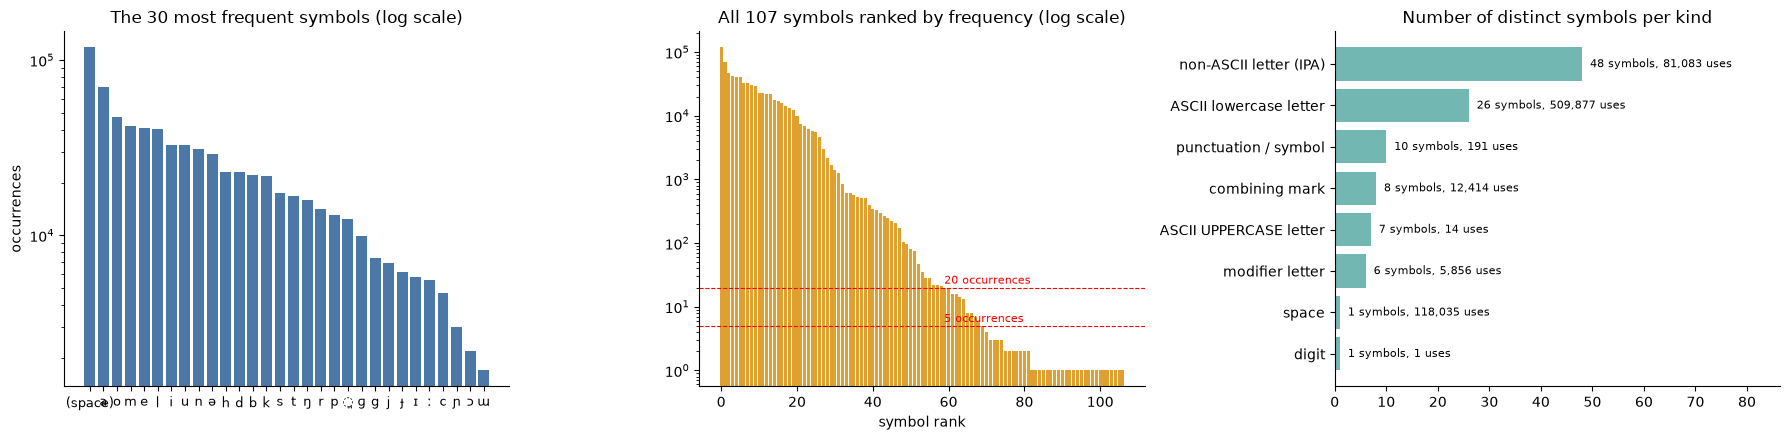

Symbols that occur fewer than 5 times : 37
Symbols that occur fewer than 20 times: 47
Number of symbols that make up 99% of all text: 33  (the remaining symbols are very rare)


In [6]:
print("=" * 100)
print("CELL C3 - PLOTS OF THE INVENTORY")
print("=" * 100)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
top = inv.head(30)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].bar(range(len(top)), top["count"], color="#4C78A8"); axes[0].set_xticks(range(len(top)), top["char"], fontsize=9)
axes[0].set_yscale("log"); axes[0].set_title("The 30 most frequent symbols (log scale)"); axes[0].set_ylabel("occurrences")
axes[1].bar(range(len(inv)), inv["count"].clip(lower=1), color="#E0A030"); axes[1].set_yscale("log")
axes[1].set_title(f"All {len(inv)} symbols ranked by frequency (log scale)"); axes[1].set_xlabel("symbol rank")
for thr in (5, 20):
    axes[1].axhline(thr, ls="--", c="red", lw=0.8); axes[1].text(len(inv) * 0.55, thr * 1.15, f"{thr} occurrences", color="red", fontsize=8)
kinds = inv.groupby("kind").agg(symbols=("char_raw", "size"), occurrences=("count", "sum")).sort_values("symbols")
axes[2].barh(kinds.index, kinds["symbols"], color="#72B7B2")
for i, (k, r) in enumerate(kinds.iterrows()): axes[2].text(r["symbols"], i, f"  {int(r['symbols'])} symbols, {int(r['occurrences']):,} uses", va="center", fontsize=8)
axes[2].set_title("Number of distinct symbols per kind"); axes[2].set_xlim(0, kinds["symbols"].max() * 1.8)
plt.tight_layout(); plt.show()
print(f"Symbols that occur fewer than 5 times : {(inv['count'] < 5).sum()}")
print(f"Symbols that occur fewer than 20 times: {(inv['count'] < 20).sum()}")
cum = inv["count"].cumsum() / inv["count"].sum()
print(f"Number of symbols that make up 99% of all text: {int((cum < 0.99).sum()) + 1}  (the remaining symbols are very rare)")

In [7]:
print("=" * 100)
print("CELL C4 - SUSPICIOUS SYMBOLS IN CONTEXT: read the words around each one")
print("=" * 100)
print("The symbol is marked like this: ⟦X⟧.  Question to ask yourself for each group: typo, annotation mark, English word, or a real part of the transcription?\n")

def show_contexts(chars, n=6, width=35, seed=0):
    for ch in chars:
        sub = tx[tx["t"].str.contains(ch, regex=False)]
        print("-" * 100)
        print(f"{shown(ch)}  {'U+%04X' % ord(ch)}  {ud.name(ch, '')}   | {int(cnt[ch])} occurrences in {len(sub)} transcripts")
        for _, r in sub.sample(min(n, len(sub)), random_state=seed).iterrows():
            i = r["t"].find(ch)
            print(f"   {r['sample_id']}  ...{r['t'][max(0, i - width):i]}⟦{ch}⟧{r['t'][i + 1:i + 1 + width]}...")

groups = [("ASCII UPPERCASE letters", "ASCII UPPERCASE letter"), ("Digits", "digit"), ("Punctuation / symbols", "punctuation / symbol"), ("Invisible / control characters", "invisible / control")]
for title, k in groups:
    chars = list(inv.loc[inv["kind"] == k, "char_raw"])
    print("=" * 100); print(f"{title}: {len(chars)} distinct symbols"); print("=" * 100)
    if chars: show_contexts(chars, n=5)
    else: print("(none found)")

CELL C4 - SUSPICIOUS SYMBOLS IN CONTEXT: read the words around each one
The symbol is marked like this: ⟦X⟧.  Question to ask yourself for each group: typo, annotation mark, English word, or a real part of the transcription?

ASCII UPPERCASE letters: 7 distinct symbols
----------------------------------------------------------------------------------------------------
A  U+0041  LATIN CAPITAL LETTER A   | 4 occurrences in 4 transcripts
   A_005648  ...mɯbul poriŋəm makin mat̪ab at̪⟦A⟧m kad̪am ɨdo hoɡab ŋahename porleh ...
   A_006292  ...aden bule kaləm həbɡado həbməbdi d̪⟦A⟧n aha tuluŋe siɟa naho ɡaleŋəm tuɡi...
   A_000352  ...o hoɡanaka didub niten habalokəm t̪⟦A⟧msir boŋe himtuluŋe pore kiminden h...
   A_000014  ...boɡu oŋa dodo ɡuɡi oŋa dodo hara t̪⟦A⟧pin jamine dodo hara hokapad̪a sikə...
----------------------------------------------------------------------------------------------------
E  U+0045  LATIN CAPITAL LETTER E   | 3 occurrences in 3 transcripts
   A_006415  ... poi ik

In [8]:
print("=" * 100)
print("CELL C5 - WHITESPACE CHECKS")
print("=" * 100)
t = tx["t"]
checks = {
    "leading or trailing space": (t != t.str.strip()),
    "two or more spaces in a row": t.str.contains("  ", regex=False),
    "tab or newline inside the text": t.str.contains(r"[\t\n\r]"),
    "non-breaking space (U+00A0)": t.str.contains("\u00a0", regex=False),
    "empty after trimming": t.str.strip() == "",
}
rep = pd.DataFrame({"transcripts affected": {k: int(v.sum()) for k, v in checks.items()},
                    "hours affected": {k: round(tx.loc[v, "hours"].sum(), 3) for k, v in checks.items()}})
display(rep)
ex = tx[checks["two or more spaces in a row"]].head(8)
print("\nExamples with a double space (the double space is shown as ⟦␣␣⟧):")
for _, r in ex.iterrows():
    i = r["t"].find("  ")
    print(f"   {r['sample_id']}  ...{r['t'][max(0, i - 30):i]}⟦␣␣⟧{r['t'][i + 2:i + 32]}...")
print("\nQuestion: does a double space mean something (a pause, a speaker change), or is it just typing noise?")

CELL C5 - WHITESPACE CHECKS


,transcripts affected,hours affected
leading or trailing space,0,0.000
two or more spaces in a row,640,3.852
tab or newline inside the text,0,0.000
non-breaking space (U+00A0),0,0.000
empty after trimming,0,0.000



Examples with a double space (the double space is shown as ⟦␣␣⟧):
   A_000002  ...i alba koisənam beŋka təna səm⟦␣␣⟧səmɟidup ta beana bendup pəca...
   A_000003  ...ne biri sigret pilajel gomiŋam⟦␣␣⟧ugub ŋun ge dimag matael iː...
   A_000004  ...c dəbaitəl eksiletaram di debo⟦␣␣⟧hor toke...
   A_000006  ...am hotam sirpa ho ŋule ho oijo⟦␣␣⟧ilaje kul siɟa alpa...
   A_000012  ...ara temiboluŋe kocho dobalokəm⟦␣␣⟧roŋɔ manbo ate hojum arəm joli...
   A_000029  ...i jekacinden ekacin boɡe kacin⟦␣␣⟧boŋekam halai tesibalai edin b...
   A_000039  ...m kəm ŋul baɟiː hɯl d̪o mad̪ən⟦␣␣⟧həb maːb d̪ɪ ŋul gə o t̪ərapəm...
   A_000051  ...ptar lo letar duku godal dodal⟦␣␣⟧ho kahaniŋ hap ka ho kahaniŋ h...

Question: does a double space mean something (a pause, a speaker change), or is it just typing noise?


CELL C6 - PLAIN 'g' vs IPA 'ɡ': is the mix random, or does it depend on who/when?
Plain Latin g is U+0067. The IPA letter ɡ is U+0261. They look almost the same. If they were used by DIFFERENT annotators or in
different recording batches, that points to an annotation inconsistency rather than two real sounds.

Total plain g: 7453   |   total IPA ɡ: 9857   |   plain g share: 43.1%
Transcripts containing BOTH symbols: 114   |  only plain g: 2084   |  only IPA ɡ: 1921

--- by recording month (each month is a recording campaign, probably transcribed in one batch) ---


,transcripts,plain_g,ipa_g,plain_share_%
rec_month,,,,
2024-11,2256,2639,1423,65.0
2025-04,1316,1016,4177,19.6
2025-06,1455,3571,1363,72.4
2025-07,181,3,928,0.3
2025-08,395,181,1965,8.4
2026-02,48,43,1,97.7



--- by speaker (only speakers with at least 30 g symbols), sorted by plain-g share ---


,transcripts,plain_g,ipa_g,plain_share_%
speaker_id,,,,
673dfcfd5cebcb2b64cec2d8,25,92,0,100.0
673f254430115fa349a330e3,58,122,0,100.0
673f2587647c6d6bf3fd8349,43,54,0,100.0
673f30c7554540458864b503,58,78,0,100.0
673f32be8c46b14f6523ae1a,56,110,0,100.0
673f31a916ece267dd18bdcf,23,60,0,100.0
673f34421f106fded16408cc,32,31,0,100.0
673f346930115fa349a33e8f,33,201,0,100.0
673f386230115fa349a33e91,40,90,0,100.0


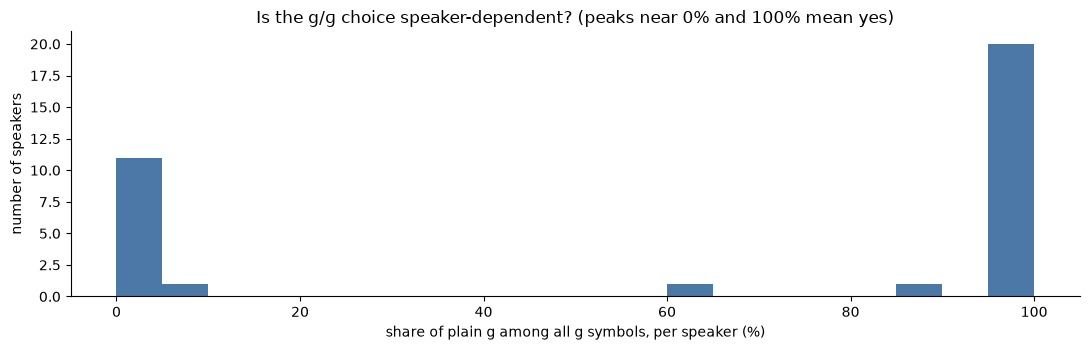

In [9]:
print("=" * 100)
print("CELL C6 - PLAIN 'g' vs IPA 'ɡ': is the mix random, or does it depend on who/when?")
print("=" * 100)
print("Plain Latin g is U+0067. The IPA letter ɡ is U+0261. They look almost the same. If they were used by DIFFERENT annotators or in")
print("different recording batches, that points to an annotation inconsistency rather than two real sounds.\n")
tx["g_plain"] = tx["t"].str.count("g"); tx["g_ipa"] = tx["t"].str.count("\u0261")
print(f"Total plain g: {int(tx['g_plain'].sum())}   |   total IPA ɡ: {int(tx['g_ipa'].sum())}   |   plain g share: {100 * tx['g_plain'].sum() / (tx['g_plain'].sum() + tx['g_ipa'].sum()):.1f}%")
both = ((tx["g_plain"] > 0) & (tx["g_ipa"] > 0)).sum()
print(f"Transcripts containing BOTH symbols: {both}   |  only plain g: {int(((tx['g_plain'] > 0) & (tx['g_ipa'] == 0)).sum())}   |  only IPA ɡ: {int(((tx['g_plain'] == 0) & (tx['g_ipa'] > 0)).sum())}")

by_m = tx.groupby("rec_month").agg(transcripts=("sample_id", "size"), plain_g=("g_plain", "sum"), ipa_g=("g_ipa", "sum"))
by_m["plain_share_%"] = (100 * by_m["plain_g"] / (by_m["plain_g"] + by_m["ipa_g"])).round(1)
print("\n--- by recording month (each month is a recording campaign, probably transcribed in one batch) ---"); display(by_m)
by_s = tx.groupby("speaker_id").agg(transcripts=("sample_id", "size"), plain_g=("g_plain", "sum"), ipa_g=("g_ipa", "sum"))
by_s = by_s[(by_s["plain_g"] + by_s["ipa_g"]) >= 30]
by_s["plain_share_%"] = (100 * by_s["plain_g"] / (by_s["plain_g"] + by_s["ipa_g"])).round(1)
print("\n--- by speaker (only speakers with at least 30 g symbols), sorted by plain-g share ---"); display(by_s.sort_values("plain_share_%", ascending=False))
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.hist(by_s["plain_share_%"], bins=20, color="#4C78A8"); ax.set_xlabel("share of plain g among all g symbols, per speaker (%)"); ax.set_ylabel("number of speakers")
ax.set_title("Is the g/ɡ choice speaker-dependent? (peaks near 0% and 100% mean yes)"); plt.tight_layout(); plt.show()

CELL C7 - DO TRANSCRIPTION HABITS CHANGE BETWEEN RECORDING MONTHS? (symbols per 1000 characters)
If a symbol is common in one month and rare in another, the month's transcriber probably used a different convention.



,clips,symbols,dental mark (U+032A),length mark ː,aspiration ʰ,nasal tilde (U+0303),ɟ,c,ʃ,dʒ (two symbols),ʒ,ɨ,ɛ,ɔ,ʈ,ə
month,,,,,,,,,,,,,,,,
2024-11,2256,204660,12.63,10.87,0.69,0.22,11.26,6.65,1.90,0.21,0.28,2.14,0.85,2.81,1.56,30.35
2025-04,1316,200195,14.94,8.88,0.31,0.00,5.55,5.86,1.31,0.50,0.51,1.15,1.17,3.87,0.08,39.67
2025-06,1455,208491,27.74,6.00,0.41,0.00,8.65,7.50,2.34,0.11,0.16,3.19,0.66,2.69,0.87,54.68
2025-07,181,35116,10.11,1.00,0.03,0.00,9.20,4.73,0.34,0.00,0.00,0.34,0.09,0.57,0.00,35.11
2025-08,395,77166,6.73,3.11,0.05,0.00,7.58,5.68,1.59,0.92,0.92,0.86,0.69,3.06,0.29,31.11
2026-02,48,1843,45.58,0.00,0.00,0.00,5.97,0.00,0.00,0.00,0.00,9.22,0.00,8.14,0.00,34.18



The same, as a plot (months on the x-axis, one line per symbol; only months with at least 20000 symbols):


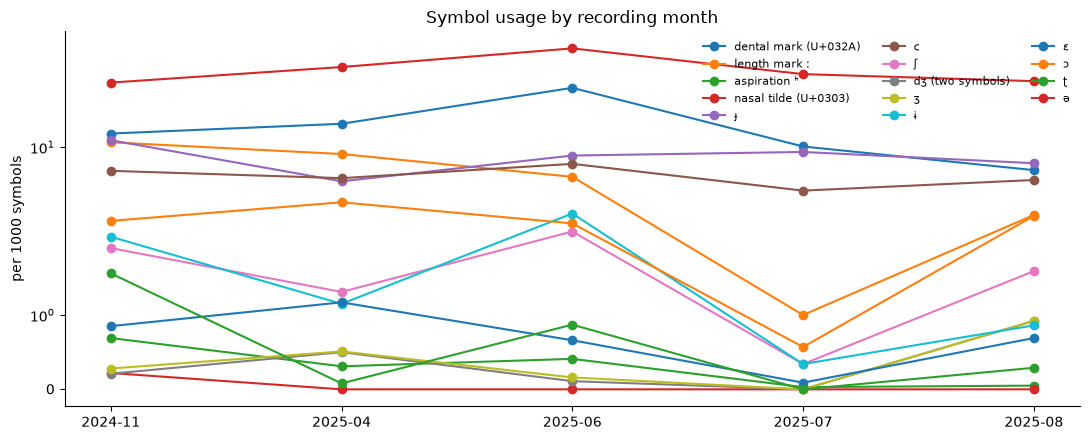

In [10]:
print("=" * 100)
print("CELL C7 - DO TRANSCRIPTION HABITS CHANGE BETWEEN RECORDING MONTHS? (symbols per 1000 characters)")
print("=" * 100)
print("If a symbol is common in one month and rare in another, the month's transcriber probably used a different convention.\n")
watch = {"dental mark (U+032A)": "\u032a", "length mark ː": "\u02d0", "aspiration ʰ": "\u02b0", "nasal tilde (U+0303)": "\u0303",
         "ɟ": "\u025f", "c": "c", "ʃ": "\u0283", "dʒ (two symbols)": "d\u0292", "ʒ": "\u0292", "ɨ": "\u0268", "ɛ": "\u025b", "ɔ": "\u0254", "ʈ": "\u0288", "ə": "\u0259"}
rows_ = []
for m, g in tx.groupby("rec_month"):
    s = "".join(g["t"]); n = max(len(s), 1)
    rows_.append({"month": m, "clips": len(g), "symbols": len(s), **{k: round(1000 * s.count(v) / n, 2) for k, v in watch.items()}})
conv = pd.DataFrame(rows_).set_index("month")
display(conv)
print("\nThe same, as a plot (months on the x-axis, one line per symbol; only months with at least 20000 symbols):")
big = conv[conv["symbols"] >= 20000]
fig, ax = plt.subplots(figsize=(11, 4.5))
for c in watch:
    if big[c].max() > 0: ax.plot(big.index, big[c], marker="o", label=c)
ax.set_ylabel("per 1000 symbols"); ax.set_yscale("symlog"); ax.legend(ncol=3, fontsize=8, frameon=False); ax.set_title("Symbol usage by recording month")
plt.tight_layout(); plt.show()

In [11]:
print("=" * 100)
print("CELL C8 - THE NORMALIZATION POLICY TABLE (draft; you decide the status of every rule)")
print("=" * 100)
print("""Statuses:  Approved = technical clean-up, safe        Pending review = may change linguistic content; needs evidence or an expert
           Rejected = would destroy information; we will not do it
Nothing in the transcripts is changed by this cell. The table only records proposals and how many clips each one would touch.\n""")
t = tx["t"]
def affected(mask): return int(mask.sum()), round(tx.loc[mask, "hours"].sum(), 3)
upper = t.str.contains("[A-Z]"); digit = t.str.contains("[0-9]")
punct_chars = set(inv.loc[inv["kind"] == "punctuation / symbol", "char_raw"])
punct = t.map(lambda s: any(c in punct_chars for c in s))
inv_chars = set(inv.loc[inv["kind"] == "invisible / control", "char_raw"])
invis = t.map(lambda s: any(c in inv_chars for c in s))
rules = [
 ("N1", "Leading/trailing spaces", "(see C5)", "trim", "none", "Approved", "C5", (t != t.str.strip())),
 ("N2", "Repeated spaces", "(see C5)", "collapse to one space", "low (check that double spaces carry no meaning)", "Approved", "C5", t.str.contains("  ", regex=False)),
 ("N3", "Unicode form", "see C2", "keep the stored form (NFD) - no change", "low", "Pending review", "C2", pd.Series(False, index=tx.index)),
 ("N4", "Plain g vs IPA ɡ", "g vs ɡ", "map g -> ɡ ?", "medium (could be two real sounds)", "Pending review", "C6", t.str.contains("g", regex=False)),
 ("N5", "Stray ASCII capital letters", "see C4", "inspect; lowercase or leave", "medium (English words, abbreviations)", "Pending review", "C4", upper),
 ("N6", "Digits", "see C4", "inspect; fix typos", "medium", "Pending review", "C4", digit),
 ("N7", "ASCII punctuation / brackets", "see C4", "inspect; delete only if not an annotation mark", "medium", "Pending review", "C4", punct),
 ("N8", "Invisible characters", "see C4", "inspect; delete if no meaning", "low", "Pending review", "C4", invis),
 ("N9", "Dental mark / affricate / vowel conventions", "see C7", "decide with experts; do not map blindly", "high", "Pending review", "C7", t.str.contains("\u032a", regex=False)),
 ("N10", "Remove combining diacritics", "any", "do NOT do this", "high (destroys phonetic information)", "Rejected", "principle", pd.Series(False, index=tx.index)),
 ("N11", "Correct apparent transcription errors", "any", "do NOT automate", "high", "Rejected", "principle", pd.Series(False, index=tx.index)),
]
pol = pd.DataFrame([dict(rule_id=r[0], issue=r[1], example=r[2], proposed_action=r[3], linguistic_risk=r[4], status=r[5], evidence=r[6],
                         rows_affected=affected(r[7])[0], hours_affected=affected(r[7])[1], reviewer="") for r in rules])
pol.to_csv(CLEAN / "normalization_policy_A.csv", index=False, encoding="utf-8-sig")
display(pol)
print("Saved to:", CLEAN / "normalization_policy_A.csv")
print("The 'reviewer' column is for the name of the expert / maintainer who confirms a rule. Change a status only with evidence.")

CELL C8 - THE NORMALIZATION POLICY TABLE (draft; you decide the status of every rule)
Statuses:  Approved = technical clean-up, safe        Pending review = may change linguistic content; needs evidence or an expert
           Rejected = would destroy information; we will not do it
Nothing in the transcripts is changed by this cell. The table only records proposals and how many clips each one would touch.



,rule_id,issue,example,proposed_action,linguistic_risk,status,evidence,rows_affected,hours_affected,reviewer
0,N1,Leading/trailing spaces,(see C5),trim,none,Approved,C5,0,0.000,
1,N2,Repeated spaces,(see C5),collapse to one space,low (check that double spaces carry no meaning),Approved,C5,640,3.852,
2,N3,Unicode form,see C2,keep the stored form (NFD) - no change,low,Pending review,C2,0,0.000,
3,N4,Plain g vs IPA ɡ,g vs ɡ,map g -> ɡ ?,medium (could be two real sounds),Pending review,C6,2198,8.454,
4,N5,Stray ASCII capital letters,see C4,inspect; lowercase or leave,"medium (English words, abbreviations)",Pending review,C4,13,0.097,
5,N6,Digits,see C4,inspect; fix typos,medium,Pending review,C4,1,0.004,
6,N7,ASCII punctuation / brackets,see C4,inspect; delete only if not an annotation mark,medium,Pending review,C4,127,0.982,
7,N8,Invisible characters,see C4,inspect; delete if no meaning,low,Pending review,C4,0,0.000,
8,N9,Dental mark / affricate / vowel conventions,see C7,decide with experts; do not map blindly,high,Pending review,C7,2631,12.957,
9,N10,Remove combining diacritics,any,do NOT do this,high (destroys phonetic information),Rejected,principle,0,0.000,


Saved to: C:\Users\Kanchan Potdar\Downloads\BTP\cleaning\normalization_policy_A.csv
The 'reviewer' column is for the name of the expert / maintainer who confirms a rule. Change a status only with evidence.


In [ ]:
print("=" * 100)
print("CELL V0 - SETUP FOR POLICY A_v2: what changes compared with A_v1, the evidence, and your confirmation")
print("=" * 100)
from pathlib import Path
import csv, datetime, re, unicodedata as ud, collections
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 60); pd.set_option("display.width", 230); pd.set_option("display.max_colwidth", 110)
import os
ROOT = Path(os.environ.get("BTP_ROOT", Path.cwd())).resolve()
MAN = ROOT / "manifests"; CLEAN = ROOT / "cleaning"; META = ROOT / "metadata"
TODAY = datetime.date.today().isoformat()
LOG = CLEAN / "decision_log_A.csv"
LOG_COLS = ["date", "step", "decision", "reason", "rows_affected", "hours_affected"]

def log_decision(step, decision, reason, rows=None, hours=None):
    """Append ONE decision to the log unless a decision with exactly this text is already there (safe to re-run)."""
    known = set(pd.read_csv(LOG, encoding="utf-8-sig")["decision"]) if LOG.exists() else set()
    if decision in known:
        print("   (already logged)", decision[:85]); return
    new_file = not LOG.exists()
    with open(LOG, "a", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        if new_file: w.writerow(LOG_COLS)
        w.writerow([TODAY, step, decision, reason, rows, hours])
    print("   logged:", decision[:85])

# --- what A_v2 starts from: the table with the A_v1 result (frozen, never modified) ---
for p in [MAN / "master_A_v1_1.parquet", MAN / "master_A_v1_2.parquet", CLEAN / "normalization_policy_A_v1.csv", LOG]:
    assert p.exists(), f"missing file: {p}"
MV = pd.read_parquet(MAN / "master_A_v1_2.parquet")
assert len(MV) == 6718 and MV["sample_id"].is_unique
HAS = ~MV["transcript_missing"]
RAW = MV.loc[HAS, "transcript_raw"]; N1 = MV.loc[HAS, "transcript_normalized"]       # raw text, and the A_v1 result
HRS = MV["duration_decoded"] / 3600
print(f"Loaded master_A_v1_2 (the A_v1 result): {len(MV)} clips, {int(HAS.sum())} with a transcript ({HRS[HAS].sum():.2f} h)")

# --- the evidence for the three punctuation marks (looked at in the A_v1 result) ---
def where(sym):
    """For one symbol: occurrences, transcripts, position inside the word, how often a combining mark follows it, and in how many of its
    transcripts the REAL glottal stop 'ʔ' also occurs."""
    n = tr = fin = ini = mid = mark = with_glottal = 0
    for t in N1:
        if sym not in t: continue
        tr += 1; with_glottal += ("\u0294" in t)
        for i, c in enumerate(t):
            if c != sym: continue
            n += 1
            nxt = t[i + 1] if i + 1 < len(t) else " "; prv = t[i - 1] if i > 0 else " "
            if nxt == " ": fin += 1
            elif prv == " ": ini += 1
            else: mid += 1
            mark += ud.category(nxt).startswith("M")
    return dict(symbol=sym, occurrences=n, transcripts=tr, word_final=fin, word_initial=ini, inside_word=mid, followed_by_combining_mark=mark, transcripts_with_real_glottal_stop=with_glottal)
EV = pd.DataFrame([where(s) for s in (".", ",", "?")]).set_index("symbol")
print("\nWhere do the three marks stand? (counted in the A_v1 result)")
display(EV)
print("""How to read it:
  '.'  every full stop is INSIDE a word, most often between two identical letters (kon.na, pjop.pa): that is the IPA SYLLABLE BREAK. It is used
       inconsistently (some of the same words are written without it), and the audio cannot tell a reader where the syllable break is.
  ','  a comma inside a word (mostly after ɡ, right before a suffix: hoɡ,e) or at the end of a word (ordinary clause punctuation). No IPA symbol looks like a comma.
  '?'  several question marks are followed by a combining mark (h-ə-b-?-mark) and some stand in transcripts that also contain the real glottal stop 'ʔ'.
       Punctuation never carries a combining mark, so many of them are probably a TYPED 'ʔ'. Deleting them would erase sounds.""")

CHANGES = pd.DataFrame([
 ("NORM_010", "full stop between two symbols of a word", "unchanged (pending)", "DELETED (provisional)", "syllable-break marker, inconsistent, no sound"),
 ("NORM_019", "comma (NEW rule)", "unchanged (pending, inside NORM_012)", "DELETED (provisional)", "no IPA reading; clause punctuation or stray marker"),
 ("NORM_011", "question mark", "unchanged (pending)", "STAYS UNCHANGED and flagged", "probably a typed glottal stop: only the maintainers can say"),
 ("NORM_012", "other punctuation  \"  =  '  \\", "unchanged (pending)", "STAYS UNCHANGED and flagged", "one occurrence each: too few for a rule"),
 ("NORM_005/006", "vowel set for the length rules", "no ʉ", "ʉ added (one shared set)", "ʉ is a vowel; no ':' or ';' follows it, so no output changes"),
 ("NORM_007", "'[' -> dental mark", "checks only the letter right before '['", "skips accents in between, like the length rules", "no output changes (all 28 '[' follow t/d directly)"),
 ("NORM_008", "g -> ɡ exception words", "exact token match", "match survives attached punctuation", "no output changes (no exception word has punctuation glued to it)"),
], columns=["rule", "what", "A_v1", "A_v2", "why"])
print("\nWHAT CHANGES IN POLICY A_v2 (everything else is identical to A_v1; rules NORM_013-NORM_018 are not touched):")
display(CHANGES)
print("Note: compared with the table I proposed in chat, the question mark is NOT deleted any more: the evidence above shows that it is probably a glottal stop.")

CONFIRM_A_V2 = True      # <- you confirmed this list in chat ("yes"). Set it to False if you want to stop here.
assert CONFIRM_A_V2, "A_v2 was not confirmed: set CONFIRM_A_V2 = True after reading the list above"
print("\nConfirmed: policy A_v2 will be created. A_v1 and master_A_v1_2 stay exactly as they are (frozen).")

In [2]:
print("=" * 100)
print("CELL V1 - THE A_v2 RULES AS FUNCTIONS, AND A DRY RUN (nothing is saved, no transcript is changed)")
print("=" * 100)
print("""All names here end in '2' on purpose: the A_v1 functions (PIPELINE, VOWELS, ...) stay untouched, so the A_v1 cells can still be re-run.
The rules run in this order:  NFD -> delete full stops inside words -> delete commas -> trim -> collapse spaces -> ':' -> ';' -> '[' -> g -> lowercase -> NFD.
""")
VOWELS2 = set("aeiouəɛɔɪʊɯɨʌæɑɒɐɜɘɵœʏʉ")                      # ONE shared vowel set (ʉ added). 'y' (19x) and 'ᵾ' (1x) are NOT added: their role is not established
G_EXCEPTION_WORDS2 = {"english", "government", "governmente", "assignment", "bekgraound", "generationga", "generationŋul", "exercisega", "exerciseiga"}   # unchanged list
PUNCT_EDGE = ".,;:?!\"'()[]=\\"                                # punctuation that may be glued to a word; used only to MATCH the exception words

def prev_base2(t, i):
    """The nearest letter before position i, skipping combining marks (accents)."""
    j = i - 1
    while j >= 0 and ud.category(t[j]).startswith("M"): j -= 1
    return t[j] if j >= 0 else ""

def r_nfd2(t):                                         # NORM_001: one Unicode form
    new = ud.normalize("NFD", t); return new, int(new != t), 0, []
def r_trim2(t):                                        # NORM_002: remove leading/trailing whitespace
    new = t.strip(); return new, int(new != t), 0, []
def r_collapse2(t):                                    # NORM_003: several ordinary spaces in a row -> one space
    new = re.sub(r" {2,}", " ", t); return new, len(t) - len(new), 0, []
def r_dot2(t):                                         # NORM_010 (NEW in A_v2): delete a full stop that stands between two symbols of one word
    out, ch, exc, det = [], 0, 0, []
    for i, c in enumerate(t):
        if c == ".":
            if 0 < i < len(t) - 1 and t[i - 1] != " " and t[i + 1] != " ": ch += 1               # inside a word: delete
            else: out.append(c); exc += 1; det.append(t[max(0, i - 8): i + 8])                     # anywhere else: keep it and flag it
        else: out.append(c)
    return "".join(out), ch, exc, det
def r_comma2(t):                                       # NORM_019 (NEW in A_v2): delete every comma
    n = t.count(","); return t.replace(",", ""), n, 0, []
def make_length_rule2(sym):                            # NORM_005 (':') and NORM_006 (';'): -> ː  only right after a vowel (shared set, accents skipped)
    def rule(t):
        out, ch, exc, det = [], 0, 0, []
        for i, c in enumerate(t):
            if c == sym:
                if prev_base2(t, i) in VOWELS2: out.append("\u02d0"); ch += 1
                else: out.append(c); exc += 1; det.append(t[max(0, i - 8): i + 8])
            else: out.append(c)
        return "".join(out), ch, exc, det
    return rule
def r_bracket2(t):                                     # NORM_007: '[' -> dental mark U+032A right after t or d; accents in between are skipped
    out, ch, exc, det = [], 0, 0, []
    for i, c in enumerate(t):
        if c == "[":
            j = i - 1
            while j >= 0 and ud.category(t[j]).startswith("M"): j -= 1
            between = t[j + 1: i]                      # accents between the letter and '['
            if j >= 0 and t[j] in ("t", "d") and "\u032a" not in between: out.append("\u032a"); ch += 1      # never create a second dental mark on the same letter
            else: out.append(c); exc += 1; det.append(t[max(0, i - 8): i + 8])
        else: out.append(c)
    return "".join(out), ch, exc, det
def r_g2(t):                                           # NORM_008: Latin g -> IPA script ɡ (U+0261), except in the English words of the list
    out, ch, exc, det = [], 0, 0, []                   # the match ignores punctuation glued to the word ('english,' is still 'english')
    for w in t.split(" "):
        n = w.count("g")
        if n and w.strip(PUNCT_EDGE).lower() in G_EXCEPTION_WORDS2: out.append(w); exc += n; det.append(w)
        else: out.append(w.replace("g", "\u0261")); ch += n
    return " ".join(out), ch, exc, det
def r_lower2(t):                                       # NORM_009: ASCII capital letters A-Z -> lowercase
    new = re.sub(r"[A-Z]", lambda m: m.group().lower(), t); return new, sum(a != b for a, b in zip(t, new)), 0, []

PIPELINE2 = [("NORM_001", r_nfd2), ("NORM_010", r_dot2), ("NORM_019", r_comma2), ("NORM_002", r_trim2), ("NORM_003", r_collapse2),
             ("NORM_005", make_length_rule2(":")), ("NORM_006", make_length_rule2(";")), ("NORM_007", r_bracket2), ("NORM_008", r_g2), ("NORM_009", r_lower2), ("NORM_001b", r_nfd2)]
def normalize_text2(t):
    """The whole A_v2 pipeline for ONE transcript."""
    for rid, fn in PIPELINE2: t = fn(t)[0]
    return t

# --- dry run on a COPY of the raw transcripts ---
stats2, examples2, exc_detail2 = {}, collections.defaultdict(list), collections.defaultdict(list)
ids = MV.loc[HAS, "sample_id"].tolist(); hrs_t = HRS[HAS].to_numpy()
cur = RAW.tolist()
for rid, fn in PIPELINE2:
    res = [fn(t) for t in cur]
    ch = np.array([r[1] for r in res]); ex = np.array([r[2] for r in res])
    stats2[rid] = dict(rows=int((ch > 0).sum()), occurrences=int(ch.sum()), exceptions=int(ex.sum()), exception_rows=int((ex > 0).sum()), hours=round(float(hrs_t[ch > 0].sum()), 3))
    for k in np.where(ch > 0)[0][:3]:
        b_, a_ = cur[k], res[k][0]; bt, at = b_.split(" "), a_.split(" ")
        d = [(x, y) for x, y in zip(bt, at) if x != y][:1] if len(bt) == len(at) else []
        examples2[rid].append(f"{ids[k]}: {d[0][0]} -> {d[0][1]}" if d else f"{ids[k]}: {b_[:30]} -> {a_[:30]}")
    for k in np.where(ex > 0)[0]: exc_detail2[rid] += [(ids[k], dd) for dd in res[k][3]]
    cur = [r[0] for r in res]
DRY2 = pd.Series(cur, index=ids)
S2 = pd.DataFrame(stats2).T.astype({"rows": int, "occurrences": int, "exceptions": int, "exception_rows": int}); S2.index.name = "rule"
print("Dry-run result per rule (rows = transcripts changed; occurrences = symbols changed or deleted; hours = audio of those transcripts, counted once):")
display(S2)

# --- the A_v2 text must differ from the A_v1 text ONLY by the deleted full stops / commas ---
def v1_to_v2(s):
    s = re.sub(r"(?<=\S)\.(?=\S)", "", s).replace(",", "")
    return re.sub(" {2,}", " ", s.strip())
same_as_v1 = [v1_to_v2(a) == b for a, b in zip(N1, DRY2)]
print(f"\nA_v2 text == A_v1 text with only the full stops inside words and the commas removed: {sum(same_as_v1)} of {len(same_as_v1)} transcripts")
assert all(same_as_v1), "A_v2 changes something else than the planned deletions: stop and look at the differing transcripts"
rep1 = pd.read_csv(CLEAN / "normalization_change_report_A_v1.csv", encoding="utf-8-sig", keep_default_na=False).set_index("rule_id")
same_nums = {r: (int(rep1.loc[r, "rows_affected"]), int(rep1.loc[r, "occurrences_changed"])) == (stats2[r]["rows"], stats2[r]["occurrences"]) for r in ["NORM_003", "NORM_005", "NORM_006", "NORM_007", "NORM_008", "NORM_009"]}
print("Rules that existed in A_v1 give the same numbers as before (rows and symbols):", same_nums)
assert all(same_nums.values())
vow_after = sum(1 for t in RAW for i, c in enumerate(t) if c in ":;" and prev_base2(t, i) == "\u0289")
print(f"ʉ added to the vowel set: {vow_after} ':' or ';' follow a ʉ, so this does not change any output (it only makes the set consistent).")

print("\nBefore -> after examples:")
for rid in ("NORM_010", "NORM_019"): print(" ", rid, "|", " ;  ".join(examples2[rid][:4]))
print("Full stops left unchanged because they are NOT inside a word:", len(exc_detail2["NORM_010"]))
print("Unchanged exceptions of the other rules:", {r: len(exc_detail2[r]) for r in ("NORM_006", "NORM_007", "NORM_008")})

CELL V1 - THE A_v2 RULES AS FUNCTIONS, AND A DRY RUN (nothing is saved, no transcript is changed)
All names here end in '2' on purpose: the A_v1 functions (PIPELINE, VOWELS, ...) stay untouched, so the A_v1 cells can still be re-run.
The rules run in this order:  NFD -> delete full stops inside words -> delete commas -> trim -> collapse spaces -> ':' -> ';' -> '[' -> g -> lowercase -> NFD.

Dry-run result per rule (rows = transcripts changed; occurrences = symbols changed or deleted; hours = audio of those transcripts, counted once):


,rows,occurrences,exceptions,exception_rows,hours
rule,,,,,
NORM_001,0,0,0,0,0.000
NORM_010,30,76,0,0,0.291
NORM_019,21,21,0,0,0.167
NORM_002,0,0,0,0,0.000
NORM_003,640,847,0,0,3.852
NORM_005,7,20,0,0,0.099
NORM_006,26,26,2,2,0.166
NORM_007,26,28,0,0,0.182
NORM_008,2195,7440,13,12,8.449



A_v2 text == A_v1 text with only the full stops inside words and the commas removed: 5651 of 5651 transcripts
Rules that existed in A_v1 give the same numbers as before (rows and symbols): {'NORM_003': True, 'NORM_005': True, 'NORM_006': True, 'NORM_007': True, 'NORM_008': True, 'NORM_009': True}
ʉ added to the vowel set: 0 ':' or ';' follow a ʉ, so this does not change any output (it only makes the set consistent).

Before -> after examples:
  NORM_010 | A_000264: cʰot̪.t̪aːme -> cʰot̪t̪aːme ;  A_000265: hok.kə -> hokkə ;  A_000770: n.ohoɡ -> nohoɡ
  NORM_019 | A_000269: bag,a -> baga ;  A_000365: hog,e -> hoge ;  A_000399: mulug, -> mulug
Full stops left unchanged because they are NOT inside a word: 0
Unchanged exceptions of the other rules: {'NORM_006': 2, 'NORM_007': 0, 'NORM_008': 12}


In [3]:
print("=" * 100)
print("CELL V2 - THE A_v2 POLICY TABLE  ->  cleaning/normalization_policy_A_v2.csv")
print("=" * 100)
print("""The A_v2 table is the A_v1 table with the changes listed in V0. Nothing in the transcripts is changed here.
Statuses: Approved = safe technical clean-up | Provisional = supported by evidence, NOT confirmed by the maintainers | Pending review | Rejected.
""")
REVIEWER = ""                      # <- type your name here if you want it recorded as the person who approves A_v2
POLICY_VERSION2 = "A_v2"
POLICY_FILE2 = CLEAN / "normalization_policy_A_v2.csv"
pol1 = pd.read_csv(CLEAN / "normalization_policy_A_v1.csv", encoding="utf-8-sig", keep_default_na=False)
POL2 = pol1.copy().set_index("rule_id")

def sym_info2(chars):
    """Transcripts containing any of the symbols, total occurrences, and the audio hours of those transcripts (in the A_v2 dry-run text)."""
    mask = DRY2.map(lambda s: any(c in s for c in chars)); joined = "".join(DRY2)
    return int(mask.sum()), sum(joined.count(c) for c in chars), round(float(HRS[HAS][mask.to_numpy()].sum()), 3)

# --- evidence for the changed rules, computed from the data ---
dots = [w for t in N1 for w in t.split(" ") if "." in w]
vocab_all = set(w2 for t in N1 for w2 in t.split(" "))
dotless = sum(1 for w in dots if "".join(w.split(".")) in vocab_all)
geminate = sum(1 for w in dots if any(a[-1:] == b[:1] for a, b in zip(w.split("."), w.split(".")[1:])))
E_dot, E_com, E_q = EV.loc["."], EV.loc[","], EV.loc["?"]
VOWEL_TXT2 = "".join(sorted(VOWELS2))
OP2 = sym_info2(['"', "=", "'", "\\"])

def setrow(rid, **kw):
    for k, v in kw.items(): POL2.loc[rid, k] = v
setrow("NORM_005", condition=f"only right after a vowel (nearest preceding letter, accents skipped); vowels: {VOWEL_TXT2}")
setrow("NORM_006", condition=f"only right after a vowel; any other semicolon is left unchanged and flagged; vowels: {VOWEL_TXT2}")
setrow("NORM_007", condition="only right after t or d (accents between the letter and '[' are skipped; if the letter already has the dental mark the '[' is left unchanged and flagged)")
setrow("NORM_008", condition="every g, except in the words of the exception list (ordinary English spellings; matched even if punctuation is glued to the word): " + ", ".join(sorted(G_EXCEPTION_WORDS2)))
setrow("NORM_010", replacement="(deleted)", condition="only a full stop between two symbols of one word (the IPA syllable break); any other full stop is left unchanged and flagged",
       evidence=f"{int(E_dot.occurrences)} occurrences in {int(E_dot.transcripts)} transcripts, all inside words (0 word-final, 0 word-initial); {geminate} of {len(dots)} dotted words have the dot between identical letters (kon.na); for {dotless} of {len(dots)} the same word also occurs without the dot: an inconsistently used syllable break that the audio cannot show",
       linguistic_risk="medium (information about syllabification is dropped)", status="Provisional", action="Apply and log", examples=" ; ".join(examples2["NORM_010"][:2]))
setrow("NORM_011", evidence=f"{int(E_q.occurrences)} occurrences: {int(E_q.inside_word)} inside a word, {int(E_q.followed_by_combining_mark)} directly followed by a combining mark, {int(E_q.transcripts_with_real_glottal_stop)} in transcripts that also contain the real glottal stop ʔ: in many cases probably a typed ʔ. NOT deleted and NOT converted: only the maintainers can say",
       action="Preserve and flag")
setrow("NORM_012", issue="Other ASCII punctuation (comma moved to NORM_019)", source_pattern="\" = ' \\", evidence="one occurrence each (A_001474, A_001275, A_005052, A_006383); meaning not established; the apostrophe in mɪlɪ'ŋŋa may be a glottal stop",
       action="Preserve and flag")
POL2["policy_version"] = POLICY_VERSION2; POL2["review_date"] = TODAY; POL2["reviewer"] = REVIEWER
POL2.loc["NORM_019"] = pd.Series(dict(issue="Comma", source_pattern=",", replacement="(deleted)", condition="every comma",
       examples=" ; ".join(examples2["NORM_019"][:2]), evidence=f"{int(E_com.occurrences)} occurrences in {int(E_com.transcripts)} transcripts: {int(E_com.inside_word)} inside a word (mostly after ɡ, before a suffix: hoɡ,e) and {int(E_com.word_final)} at the end of a word (clause punctuation); no IPA symbol looks like a comma",
       linguistic_risk="medium (a stray marker might carry a meaning nobody has documented)", status="Provisional", action="Apply and log", reviewer=REVIEWER, review_date=TODAY, policy_version=POLICY_VERSION2,
       dry_run_rows=0, dry_run_occurrences=0, dry_run_exceptions=0, dry_run_hours=0.0))
# dry-run columns: the numbers of THIS dry run for every rule that is applied; for the preserved symbols the counts of the A_v2 text
for rid in ["NORM_001", "NORM_002", "NORM_003", "NORM_005", "NORM_006", "NORM_007", "NORM_008", "NORM_009", "NORM_010", "NORM_019"]:
    s = stats2[rid]; POL2.loc[rid, ["dry_run_rows", "dry_run_occurrences", "dry_run_exceptions", "dry_run_hours"]] = [s["rows"], s["occurrences"], s["exceptions"], s["hours"]]
POL2.loc["NORM_011", ["dry_run_rows", "dry_run_occurrences", "dry_run_exceptions", "dry_run_hours"]] = [*sym_info2(["?"])[:2], 0, sym_info2(["?"])[2]]
POL2.loc["NORM_012", ["dry_run_rows", "dry_run_occurrences", "dry_run_exceptions", "dry_run_hours"]] = [*OP2[:2], 0, OP2[2]]
POL2 = POL2.reset_index()[list(pol1.columns)].sort_values("rule_id").reset_index(drop=True)
for c in ["dry_run_rows", "dry_run_occurrences", "dry_run_exceptions"]: POL2[c] = POL2[c].astype(int)
POL2["dry_run_hours"] = POL2["dry_run_hours"].astype(float)

KEY = ["rule_id", "source_pattern", "replacement", "condition", "status", "action"]
if POLICY_FILE2.exists():
    old2 = pd.read_csv(POLICY_FILE2, encoding="utf-8-sig", keep_default_na=False)
    if old2[KEY].astype(str).reset_index(drop=True).equals(POL2[KEY].astype(str).reset_index(drop=True)):
        print(f"{POLICY_FILE2.name} already exists and its rules are identical: NOT rewritten (a frozen version is never edited).")
    else:
        alt = CLEAN / "normalization_policy_A_v2_PROPOSED_CHANGES.csv"; POL2.to_csv(alt, index=False, encoding="utf-8-sig")
        print(f"{POLICY_FILE2.name} exists and the rules DIFFER. It was not overwritten; the new version was saved as {alt.name}. A change after A_v2 is applied means A_v3.")
else:
    POL2.to_csv(POLICY_FILE2, index=False, encoding="utf-8-sig"); print("Saved:", POLICY_FILE2)
print("\nThe A_v2 policy table (key columns):")
display(POL2[["rule_id", "issue", "source_pattern", "replacement", "status", "action", "dry_run_rows", "dry_run_occurrences", "dry_run_exceptions", "dry_run_hours"]])
print("\nRules that differ from A_v1 (what the evidence says):")
for rid in ["NORM_010", "NORM_011", "NORM_012", "NORM_019"]: print(f"  {rid} [{POL2.loc[POL2.rule_id == rid, 'status'].iloc[0]}] {POL2.loc[POL2.rule_id == rid, 'evidence'].iloc[0]}")
print("\nStatus counts:", POL2["status"].value_counts().to_dict())

CELL V2 - THE A_v2 POLICY TABLE  ->  cleaning/normalization_policy_A_v2.csv
The A_v2 table is the A_v1 table with the changes listed in V0. Nothing in the transcripts is changed here.
Statuses: Approved = safe technical clean-up | Provisional = supported by evidence, NOT confirmed by the maintainers | Pending review | Rejected.

Saved: C:\Users\Kanchan Potdar\Downloads\BTP\cleaning\normalization_policy_A_v2.csv

The A_v2 policy table (key columns):


,rule_id,issue,source_pattern,replacement,status,action,dry_run_rows,dry_run_occurrences,dry_run_exceptions,dry_run_hours
0,NORM_001,Unicode representation,any text,NFD (decomposed form),Approved,Apply,0,0,0,0.000
1,NORM_002,Leading/trailing whitespace,space at either end,(removed),Approved,Apply,0,0,0,0.000
2,NORM_003,Repeated spaces,two or more spaces in a row,one space,Approved,Apply,640,847,0,3.852
3,NORM_004,Invisible characters,"zero-width, control, non-breaking space",(none),Approved,Check only,0,0,0,0.000
4,NORM_005,Colon typed instead of length mark,:,ː (U+02D0),Provisional,Apply and log,7,20,0,0.099
5,NORM_006,Semicolon typed instead of length mark,;,ː (U+02D0),Provisional,Apply and log,26,26,2,0.166
6,NORM_007,Square bracket typed instead of dental mark,[,combining dental mark U+032A,Provisional,Apply and log,26,28,0,0.182
7,NORM_008,Latin g vs IPA script g,g (U+0067),ɡ (U+0261),Provisional,Apply and log,2195,7440,13,8.449
8,NORM_009,ASCII capital letters,A-Z,a-z,Provisional,Apply and log,13,14,0,0.097
9,NORM_010,Full stop inside words,.,(deleted),Provisional,Apply and log,30,76,0,0.291



Rules that differ from A_v1 (what the evidence says):
  NORM_010 [Provisional] 76 occurrences in 30 transcripts, all inside words (0 word-final, 0 word-initial); 61 of 75 dotted words have the dot between identical letters (kon.na); for 21 of 75 the same word also occurs without the dot: an inconsistently used syllable break that the audio cannot show
  NORM_011 [Pending review] 14 occurrences: 7 inside a word, 4 directly followed by a combining mark, 9 in transcripts that also contain the real glottal stop ʔ: in many cases probably a typed ʔ. NOT deleted and NOT converted: only the maintainers can say
  NORM_012 [Pending review] one occurrence each (A_001474, A_001275, A_005052, A_006383); meaning not established; the apostrophe in mɪlɪ'ŋŋa may be a glottal stop
  NORM_019 [Provisional] 21 occurrences in 21 transcripts: 13 inside a word (mostly after ɡ, before a suffix: hoɡ,e) and 8 at the end of a word (clause punctuation); no IPA symbol looks like a comma

Status counts: {'Provisio

In [4]:
print("=" * 100)
print("CELL V3 - APPLY A_v2: build transcript_normalized (transcript_raw is NOT touched)  ->  master_A_v1_3")
print("=" * 100)
print("""Every transcript goes through the A_v2 pipeline on a working copy; we remember which rule changed what. The result goes into a NEW file
(master_A_v1_3). master_A_v1_2 (the A_v1 result) and master_A_v1_1 are not modified. The three normalization columns are rebuilt under A_v2.
In the change list, 'n' = number of SYMBOLS changed or deleted (NORM_001/002: 1 if the transcript changed; NORM_003: number of spaces removed).
""")
assert CONFIRM_A_V2, "run cell V0 first"
assert MV["transcript_raw"].map(lambda x: isinstance(x, str)).all()
def example_pair2(rid, before, after):
    if rid == "NORM_003":
        i = before.find("  "); b = before[max(0, i - 12): i + 14]; return b.replace("  ", "\u2423\u2423"), re.sub(" {2,}", " ", b)
    bt, at = before.split(" "), after.split(" ")
    if len(bt) == len(at):
        d = [(x, y) for x, y in zip(bt, at) if x != y]
        if d: return d[0]
    return before[:30], after[:30]

norm2, applied2, excs2, changes2 = [], [], [], []
for sid, raw, miss in zip(MV["sample_id"], MV["transcript_raw"], MV["transcript_missing"]):
    if miss: norm2.append(None); applied2.append(None); excs2.append(None); continue
    cur, a, e = raw, [], []
    for rid, fn in PIPELINE2:
        new, ch, ex, det = fn(cur)
        if ch > 0:
            a.append(rid); b_, a_ = example_pair2(rid, cur, new)
            changes2.append(dict(sample_id=sid, rule_id=rid, kind="changed", n=ch, before=b_, after=a_))
        if ex > 0:
            e.append(f"{rid}:{ex}"); changes2.append(dict(sample_id=sid, rule_id=rid, kind="exception", n=ex, before=" | ".join(det), after=""))
        cur = new
    norm2.append(cur); applied2.append(";".join(a) or None); excs2.append(";".join(e) or None)
CH2 = pd.DataFrame(changes2)
M3 = MV.copy()
M3["transcript_normalized"] = norm2
M3["normalization_policy_version"] = np.where(M3["transcript_missing"], None, POLICY_VERSION2)
M3["normalization_rules_applied"] = applied2
M3["normalization_exceptions"] = excs2

OUT13 = MAN / "master_A_v1_3.parquet"; NEWCOLS = ["sample_id", "transcript_normalized", "normalization_policy_version", "normalization_rules_applied", "normalization_exceptions"]
if OUT13.exists():
    prev = pd.read_parquet(OUT13)
    assert prev[NEWCOLS].fillna("<NA>").astype(str).equals(M3[NEWCOLS].fillna("<NA>").astype(str)), "master_A_v1_3 already exists with DIFFERENT content. A_v2 is frozen: a change means A_v3."
    print("master_A_v1_3 already exists and is identical to the result of this run: nothing was rewritten.")
else:
    M3.to_parquet(OUT13, index=False); M3.to_csv(MAN / "master_A_v1_3.csv", index=False, encoding="utf-8-sig")
    CH2.to_csv(CLEAN / "normalization_row_changes_A_v2.csv", index=False, encoding="utf-8-sig")
    print("Saved: master_A_v1_3.parquet / .csv and cleaning/normalization_row_changes_A_v2.csv")

has2 = ~M3["transcript_missing"]
changed2 = has2 & (M3["transcript_normalized"] != M3["transcript_raw"])
changed_vs_v1 = has2 & (M3["transcript_normalized"] != MV["transcript_normalized"])
print(f"\nTranscripts normalized                         : {int(has2.sum())}")
print(f"  changed by >= 1 rule compared with the RAW text : {int(changed2.sum())}  ({HRS[changed2].sum():.3f} h)    (A_v1 had 2,487)")
print(f"  differing from the A_v1 text (full stops/commas): {int(changed_vs_v1.sum())}  ({HRS[changed_vs_v1].sum():.3f} h)")
print(f"Clips without transcript (empty)                : {int((~has2).sum())}")
print("\nFive random transcripts that A_v2 changed compared with A_v1:")
for _, r in M3[changed_vs_v1].sample(5, random_state=2).iterrows():
    a1 = MV.loc[MV.sample_id == r["sample_id"], "transcript_normalized"].iloc[0]
    diff = [(x, y) for x, y in zip(a1.split(" "), r["transcript_normalized"].split(" ")) if x != y][:3]       # the words that differ (the deletions never change the number of words)
    print(f"  {r['sample_id']} | A_v2 rules: {r['normalization_rules_applied']} | changed words (A_v1 -> A_v2): " + " ; ".join(f"{x} -> {y}" for x, y in diff))

CELL V3 - APPLY A_v2: build transcript_normalized (transcript_raw is NOT touched)  ->  master_A_v1_3
Every transcript goes through the A_v2 pipeline on a working copy; we remember which rule changed what. The result goes into a NEW file
(master_A_v1_3). master_A_v1_2 (the A_v1 result) and master_A_v1_1 are not modified. The three normalization columns are rebuilt under A_v2.
In the change list, 'n' = number of SYMBOLS changed or deleted (NORM_001/002: 1 if the transcript changed; NORM_003: number of spaces removed).

Saved: master_A_v1_3.parquet / .csv and cleaning/normalization_row_changes_A_v2.csv

Transcripts normalized                         : 5651
  changed by >= 1 rule compared with the RAW text : 2495  (10.383 h)    (A_v1 had 2,487)
  differing from the A_v1 text (full stops/commas): 51  (0.459 h)
Clips without transcript (empty)                : 1067

Five random transcripts that A_v2 changed compared with A_v1:
  A_006168 | A_v2 rules: NORM_010;NORM_003;NORM_008 | changed wor

In [5]:
print("=" * 100)
print("CELL V4 - VALIDATE THE A_v2 RESULT (every check must pass before we trust the new column)")
print("=" * 100)
print("""(1) Consistency checks on the whole table. (2) A CHARACTER-LEVEL AUDIT that is written INDEPENDENTLY of the rule functions (regular expressions instead of
loops): every changed character must be one that a rule may change, where the rule applies, and every place where a rule applies must really have been changed.
Passing shows that the rules were applied correctly. It does NOT show that they are linguistically right: that needs the maintainers or a Nyishi speaker.
""")
chk2 = pd.read_parquet(MAN / "master_A_v1_3.parquet")
t_raw2, t_new2 = chk2.loc[has2, "transcript_raw"], chk2.loc[has2, "transcript_normalized"]
allnew2, allraw2 = "".join(t_new2), "".join(t_raw2)
comb = lambda s: sum(ud.category(c).startswith("M") for c in s)
exc_counts2 = {r: int(CH2[(CH2.rule_id == r) & (CH2.kind == "exception")]["n"].sum()) for r in ("NORM_005", "NORM_006", "NORM_007", "NORM_008", "NORM_010")}
ALLOWED2 = {(":", "\u02d0"), (";", "\u02d0"), ("[", "\u032a"), ("g", "\u0261")}

def char_audit2(raw, new):
    """Audit ONE transcript. Returns a list of problems (empty = every change is allowed and nothing that should change was missed)."""
    base = ud.normalize("NFD", raw)
    base = re.sub(r"(?<=\S)\.(?=\S)", "", base)                 # the planned deletions, written with regular expressions
    base = base.replace(",", "")
    base = re.sub(" {2,}", " ", base.strip())                   # the only other step that changes the length
    if len(base) != len(new): return ["length differs after the planned deletions and the removal of repeated spaces"]
    spans = [(m.start(), m.end(), m.group()) for m in re.finditer(r"[^ ]+", base)]
    def in_exception(i): return any(s <= i < e and w.strip(PUNCT_EDGE).lower() in G_EXCEPTION_WORDS2 for s, e, w in spans)
    def bracket_applies(i):
        j = i - 1
        while j >= 0 and ud.category(base[j]).startswith("M"): j -= 1
        return j >= 0 and base[j] in ("t", "d") and "\u032a" not in base[j + 1: i]
    problems = []
    for i, (a, b) in enumerate(zip(base, new)):
        if a == b:
            if a in ":;" and prev_base2(base, i) in VOWELS2: problems.append(f"{a!r} after a vowel was not converted (position {i})")
            elif a == "[" and bracket_applies(i): problems.append(f"'[' after t/d was not converted (position {i})")
            elif a == "g" and not in_exception(i): problems.append(f"g outside the exception list was not converted (position {i})")
            elif "A" <= a <= "Z": problems.append(f"a capital letter was not lowercased (position {i})")
        elif (a, b) in ALLOWED2:
            if a in ":;" and prev_base2(base, i) not in VOWELS2: problems.append(f"{a!r} converted although no vowel precedes it (position {i})")
            elif a == "[" and not bracket_applies(i): problems.append(f"'[' converted although the condition does not hold (position {i})")
            elif a == "g" and in_exception(i): problems.append(f"g converted inside an exception word (position {i})")
        elif "A" <= a <= "Z" and b == a.lower(): pass
        else: problems.append(f"UNEXPECTED change {a!r} -> {b!r} (position {i})")
    return problems
audit2 = {sid: char_audit2(r, n) for sid, r, n in zip(chk2.loc[has2, "sample_id"], t_raw2, t_new2)}
bad_audit2 = {k: v for k, v in audit2.items() if v}
glued2 = [(sid, w) for sid, t in zip(chk2.loc[has2, "sample_id"], t_raw2) for w in t.split(" ") if "g" in w and w.strip(PUNCT_EDGE).lower() in G_EXCEPTION_WORDS2 and w.lower() not in G_EXCEPTION_WORDS2]

old11 = pd.read_parquet(MAN / "master_A_v1_1.parquet")
rule_ok2 = {
  "NORM_001": bool((t_new2 == t_new2.map(lambda s: ud.normalize("NFD", s))).all()),
  "NORM_002": bool(not t_new2.str.contains(r"^ | $", regex=True).any()),
  "NORM_003": bool(not t_new2.str.contains("  ", regex=False).any()),
  "NORM_005": allnew2.count(":") == exc_counts2["NORM_005"],
  "NORM_006": allnew2.count(";") == exc_counts2["NORM_006"],
  "NORM_007": allnew2.count("[") == exc_counts2["NORM_007"] and comb(allnew2) == comb(allraw2) + int(CH2[(CH2.rule_id == "NORM_007") & (CH2.kind == "changed")]["n"].sum()),
  "NORM_008": all(w.strip(PUNCT_EDGE).lower() in G_EXCEPTION_WORDS2 for t in t_new2 for w in t.split(" ") if "g" in w),
  "NORM_009": bool(not t_new2.str.contains(r"[A-Z]", regex=True).any()),
  "NORM_010": bool(not t_new2.str.contains(r"(?<=\S)\.(?=\S)", regex=True).any()) and allnew2.count(".") == exc_counts2["NORM_010"],
  "NORM_019": "," not in allnew2,
}
in_pipeline2 = {rid for rid, _ in PIPELINE2 if rid != "NORM_001b"}
agree2 = {}
for r in sorted(in_pipeline2):
    c = CH2[(CH2.rule_id == r) & (CH2.kind == "changed")]; p = POL2[POL2.rule_id == r].iloc[0]
    hrs = float(HRS[MV["sample_id"].isin(c["sample_id"]).to_numpy()].sum())
    agree2[r] = bool(c["sample_id"].nunique() == p["dry_run_rows"] and int(c["n"].sum()) == p["dry_run_occurrences"]
                     and int(CH2[(CH2.rule_id == r) & (CH2.kind == "exception")]["n"].sum()) == p["dry_run_exceptions"] and abs(hrs - float(p["dry_run_hours"])) < 0.0015)
checks2 = {
  "transcript_raw is identical to version 1.2 (and 1.1)": chk2["transcript_raw"].equals(MV["transcript_raw"]) and chk2["transcript_raw"].equals(old11["transcript_raw"]),
  "every transcript has a normalized version": bool(t_new2.notna().all() and (t_new2.str.len() > 0).all()),
  "clips without a transcript stay empty": bool(chk2.loc[~has2, "transcript_normalized"].isna().all()),
  "all other columns of version 1.2 are unchanged": all(chk2[c].fillna("<NA>").astype(str).equals(MV[c].fillna("<NA>").astype(str)) for c in MV.columns if c not in NEWCOLS),
  "the text is valid Unicode (UTF-8 round trip)": all(s.encode("utf-8").decode("utf-8") == s for s in t_new2),
  "combining marks: none removed, exactly the ones from '[' added": comb(allnew2) == comb(allraw2) + int(CH2[(CH2.rule_id == "NORM_007") & (CH2.kind == "changed")]["n"].sum()),
  "word count unchanged: no word was merged, split or lost": int(t_raw2.str.split().str.len().sum()) == int(t_new2.str.split().str.len().sum()),
  "A_v2 text == A_v1 text minus the full stops inside words and the commas (all rows)": all(v1_to_v2(a) == b for a, b in zip(MV.loc[has2, "transcript_normalized"], t_new2)),
  "the question mark is untouched: same number as in the raw text": allnew2.count("?") == allraw2.count("?"),
  "CHARACTER-LEVEL AUDIT: every change is allowed, nothing that should change was missed": len(bad_audit2) == 0,
  "every changed transcript is traceable to a rule": bool(chk2.loc[changed2, "normalization_rules_applied"].notna().all()),
  "every transcript with a rule recorded really changed": bool(((chk2["normalization_rules_applied"].notna()) <= changed2).all()),
  "re-running the pipeline on the raw text gives identical text": all(normalize_text2(a) == b for a, b in zip(t_raw2, t_new2)),
  "running it again on the normalized text changes nothing": all(normalize_text2(b) == b for b in t_new2),
  "the policy version A_v2 is recorded on every normalized row": bool((chk2.loc[has2, "normalization_policy_version"] == POLICY_VERSION2).all()),
  "all 10 rule-level checks pass": len(rule_ok2) == 10 and all(rule_ok2.values()),
  "the numbers of all 10 rules agree with the dry run stored in the A_v2 policy file": len(agree2) == 10 and all(agree2.values()),
}
for k, v in checks2.items(): print(("PASS  " if v else "FAIL  ") + k)
print("\nRule-level checks:", rule_ok2); print("Agreement with dry run per rule:", agree2)
print("Exception words that have punctuation glued to them (matched by A_v2, would have been missed by A_v1):", len(glued2))
if bad_audit2:
    print(f"\nCharacter-level problems in {len(bad_audit2)} transcripts; the first 5:")
    for k in list(bad_audit2)[:5]: print("  ", k, bad_audit2[k][:3])
assert all(checks2.values()), "at least one check failed - read the FAIL lines above and do not use the new column yet"
b_sym, a_sym = collections.Counter(allraw2), collections.Counter(allnew2)
print(f"\nDistinct symbols: raw {len(b_sym)} -> A_v2 text {len(a_sym)}  (A_v1 text had 98)")
print("Symbols that disappeared:", {c: n for c, n in b_sym.items() if c not in a_sym})
print("Symbols that are NEW      :", {c: n for c, n in a_sym.items() if c not in b_sym} or "(none)")
print("Full stops / commas left in the text:", a_sym["."], "/", a_sym[","], "| question marks:", a_sym["?"], "(unchanged)")

CELL V4 - VALIDATE THE A_v2 RESULT (every check must pass before we trust the new column)
(1) Consistency checks on the whole table. (2) A CHARACTER-LEVEL AUDIT that is written INDEPENDENTLY of the rule functions (regular expressions instead of
loops): every changed character must be one that a rule may change, where the rule applies, and every place where a rule applies must really have been changed.
Passing shows that the rules were applied correctly. It does NOT show that they are linguistically right: that needs the maintainers or a Nyishi speaker.

PASS  transcript_raw is identical to version 1.2 (and 1.1)
PASS  every transcript has a normalized version
PASS  clips without a transcript stay empty
PASS  all other columns of version 1.2 are unchanged
PASS  the text is valid Unicode (UTF-8 round trip)
PASS  combining marks: none removed, exactly the ones from '[' added
PASS  word count unchanged: no word was merged, split or lost
PASS  A_v2 text == A_v1 text minus the full stops insi

In [6]:
print("=" * 100)
print("CELL V5 - CHANGE REPORT FOR A_v2, AND THE NEW COUNT OF TRANSCRIPTS THAT STILL NEED A HUMAN LOOK")
print("=" * 100)
print("""Part 1 - the change report (one line per rule). rows_affected = DIFFERENT transcripts changed; occurrences_changed = symbols changed or deleted;
hours_affected = audio of those transcripts, counted once. Rules that existed in A_v1 must show the same numbers as in the A_v1 report.
Part 2 - the review list: transcripts that still contain punctuation, a digit or a rare symbol (a review signal, not proof of an error).
This cell only counts and saves lists. Nothing is flagged in the master table and nothing is excluded from validation/test yet.
""")
def validation_of2(r): return "Not checked" if (r not in rule_ok2 or r not in agree2) else ("Yes" if (rule_ok2[r] and agree2[r]) else "No")
rep2 = []
for _, p in POL2[POL2["rule_id"].isin(sorted(in_pipeline2))].iterrows():
    r = p["rule_id"]; c = CH2[(CH2.rule_id == r) & (CH2.kind == "changed")]; e = CH2[(CH2.rule_id == r) & (CH2.kind == "exception")]
    rep2.append(dict(rule_id=r, issue=p["issue"], policy_version=POLICY_VERSION2, status=p["status"], rows_affected=int(c["sample_id"].nunique()), occurrences_changed=int(c["n"].sum()),
                     hours_affected=round(float(HRS[MV["sample_id"].isin(c["sample_id"]).to_numpy()].sum()), 3), exceptions_flagged=int(e["n"].sum()), exception_rows=int(e["sample_id"].nunique()),
                     examples_before=" | ".join(f"{s}: {b}" for s, b in zip(c["sample_id"].head(3), c["before"].head(3))), examples_after=" | ".join(f"{s}: {a}" for s, a in zip(c["sample_id"].head(3), c["after"].head(3))),
                     exception_examples=" | ".join(f"{s}: {b}" for s, b in zip(e["sample_id"].head(3), e["before"].head(3))), validation_passed=validation_of2(r)))
REP2 = pd.DataFrame(rep2)
anyc2 = CH2[CH2.kind == "changed"]["sample_id"].unique()
REP2 = pd.concat([REP2, pd.DataFrame([dict(rule_id="ALL RULES (distinct)", issue="transcripts changed by at least one rule", policy_version=POLICY_VERSION2, status="", rows_affected=len(anyc2),
      occurrences_changed=int(CH2[CH2.kind == "changed"]["n"].sum()), hours_affected=round(float(HRS[MV["sample_id"].isin(anyc2).to_numpy()].sum()), 3), exceptions_flagged=int(CH2[CH2.kind == "exception"]["n"].sum()),
      exception_rows=int(CH2[CH2.kind == "exception"]["sample_id"].nunique()), examples_before="", examples_after="", exception_examples="", validation_passed="Yes" if all(checks2.values()) else "No")])], ignore_index=True)
REP2.to_csv(CLEAN / "normalization_change_report_A_v2.csv", index=False, encoding="utf-8-sig")
display(REP2[["rule_id", "issue", "status", "rows_affected", "occurrences_changed", "hours_affected", "exceptions_flagged", "validation_passed"]])
print("Note: the last line counts every transcript once, so it is NOT the sum of the lines above.")
print("\nBefore -> after examples of the two NEW rules (look at them: the checks cannot judge whether a change is linguistically right):")
for _, r in REP2[REP2.rule_id.isin(["NORM_010", "NORM_019"])].iterrows(): print(f"  {r['rule_id']}\n      before: {r['examples_before'][:150]}\n      after : {r['examples_after'][:150]}")
print("\nSaved: cleaning/normalization_change_report_A_v2.csv")

# ---- part 2: the review list ----
ACCEPTED_SYMBOLS2 = set()           # e.g. {"ɜ", "ɬ"} after a reviewer has looked at the examples and accepted them
cn2 = collections.Counter(allnew2)
rare2 = {c for c, n in cn2.items() if n < 5 and c != " " and (not c.isascii() or c.islower()) and c not in ACCEPTED_SYMBOLS2}
def reasons2(s):
    r = []
    for c in sorted(set(s)):
        if c in ACCEPTED_SYMBOLS2: continue
        if c.isascii() and c.isdigit(): r.append(("digit", c))
        elif c.isascii() and not c.isalnum() and c != " ": r.append(("punctuation", c))
        elif c in rare2: r.append(("rare symbol", c))
    return r
U2 = chk2.loc[has2, ["sample_id", "original_split", "speaker_status", "duration_decoded", "transcript_normalized"]].copy()
U2["why"] = U2["transcript_normalized"].map(reasons2); U2 = U2[U2["why"].map(len) > 0].copy()
U2["categories"] = U2["why"].map(lambda r: "; ".join(sorted({k for k, _ in r})))
U2["symbols"] = U2["why"].map(lambda r: "; ".join(f"{k} {c} (U+{ord(c):04X})" for k, c in r)); U2["hours"] = U2["duration_decoded"] / 3600
u1 = pd.read_csv(CLEAN / "unresolved_symbol_rows_A_v1.csv", encoding="utf-8-sig", keep_default_na=False)
print(f"\nTranscripts that still need a look under A_v2: {len(U2)}  ({U2['hours'].sum():.2f} h = {100 * len(U2) / int(has2.sum()):.1f}% of the transcribed clips)")
print(f"Under A_v1 it was {len(u1)} transcripts (0.74 h). Resolved by A_v2: {len(set(u1.sample_id) - set(U2.sample_id))}; new: {len(set(U2.sample_id) - set(u1.sample_id))}")
print("\nBy category (a transcript can be in several):"); display(pd.Series(collections.Counter(k for r in U2["why"] for k in {x for x, _ in r})).rename("transcripts").to_frame())
print("By original split (they must stay out of validation/test until reviewed):"); display(U2["original_split"].value_counts().rename("transcripts").to_frame())
sym_rows2 = collections.defaultdict(list)
for sid, why, txt in zip(U2["sample_id"], U2["why"], U2["transcript_normalized"]):
    for k, c in why: sym_rows2[(k, c)].append((sid, txt))
S4b = pd.DataFrame([dict(category=k, symbol=c, code=f"U+{ord(c):04X}", transcripts=len(v), example=f"{v[0][0]}: {v[0][1][:60]}") for (k, c), v in sym_rows2.items()]).sort_values(["category", "transcripts"], ascending=[True, False])
print("Every symbol that causes a flag:"); display(S4b)
U2[["sample_id", "original_split", "speaker_status", "hours", "categories", "symbols", "transcript_normalized"]].to_csv(CLEAN / "unresolved_symbol_rows_A_v2.csv", index=False, encoding="utf-8-sig")
S4b.to_csv(CLEAN / "unresolved_symbol_summary_A_v2.csv", index=False, encoding="utf-8-sig")
print("Saved: cleaning/unresolved_symbol_rows_A_v2.csv and cleaning/unresolved_symbol_summary_A_v2.csv")

CELL V5 - CHANGE REPORT FOR A_v2, AND THE NEW COUNT OF TRANSCRIPTS THAT STILL NEED A HUMAN LOOK
Part 1 - the change report (one line per rule). rows_affected = DIFFERENT transcripts changed; occurrences_changed = symbols changed or deleted;
hours_affected = audio of those transcripts, counted once. Rules that existed in A_v1 must show the same numbers as in the A_v1 report.
Part 2 - the review list: transcripts that still contain punctuation, a digit or a rare symbol (a review signal, not proof of an error).
This cell only counts and saves lists. Nothing is flagged in the master table and nothing is excluded from validation/test yet.



,rule_id,issue,status,rows_affected,occurrences_changed,hours_affected,exceptions_flagged,validation_passed
0,NORM_001,Unicode representation,Approved,0,0,0.000,0,Yes
1,NORM_002,Leading/trailing whitespace,Approved,0,0,0.000,0,Yes
2,NORM_003,Repeated spaces,Approved,640,847,3.852,0,Yes
3,NORM_005,Colon typed instead of length mark,Provisional,7,20,0.099,0,Yes
4,NORM_006,Semicolon typed instead of length mark,Provisional,26,26,0.166,2,Yes
5,NORM_007,Square bracket typed instead of dental mark,Provisional,26,28,0.182,0,Yes
6,NORM_008,Latin g vs IPA script g,Provisional,2195,7440,8.449,13,Yes
7,NORM_009,ASCII capital letters,Provisional,13,14,0.097,0,Yes
8,NORM_010,Full stop inside words,Provisional,30,76,0.291,0,Yes
9,NORM_019,Comma,Provisional,21,21,0.167,0,Yes


Note: the last line counts every transcript once, so it is NOT the sum of the lines above.

Before -> after examples of the two NEW rules (look at them: the checks cannot judge whether a change is linguistically right):
  NORM_010
      before: A_000264: cʰot̪.t̪aːme | A_000265: hok.kə | A_000770: n.ohoɡ
      after : A_000264: cʰot̪t̪aːme | A_000265: hokkə | A_000770: nohoɡ
  NORM_019
      before: A_000269: bag,a | A_000365: hog,e | A_000399: mulug,
      after : A_000269: baga | A_000365: hoge | A_000399: mulug

Saved: cleaning/normalization_change_report_A_v2.csv

Transcripts that still need a look under A_v2: 52  (0.28 h = 0.9% of the transcribed clips)
Under A_v1 it was 103 transcripts (0.74 h). Resolved by A_v2: 51; new: 0

By category (a transcript can be in several):


,transcripts
punctuation,20
rare symbol,31
digit,1


By original split (they must stay out of validation/test until reviewed):


,transcripts
original_split,
train,44
validation,7
test,1


Every symbol that causes a flag:


,category,symbol,code,transcripts,example
16,digit,0,U+0030,1,A_003884: ŋul ɡə rolu d̪ulu ho hoɡ eɟukeʃən sɪst̪əm həl d̪0 mad̪ən həb
0,punctuation,?,U+003F,14,A_000240: laːjsɪz maːhŋo niːj t̪e ət̪? neka nezəh nə maːlaːj ɔ
1,punctuation,;,U+003B,2,A_001165: hebma sika alɟis doŋɔme masi mebulbe bename kajt̪ami mul nis
2,punctuation,=,U+003D,1,A_001275: bə=paŋe lindo ek cari mojna tini mojna hab laɡido
3,punctuation,"""",U+0022,1,A_001474: o mul hɛd mɑːstəre ɟorəm ɟekie aʋo səːr heŋuləm aleɟ porəi ɡ
23,punctuation,',U+0027,1,A_005052: mɪlɪŋŋʌ aːlsud̪ad̪ʌn iːm mɪlɪ'ŋŋa soːnakʌnʌm julus ɟiːmiːmʌm
30,punctuation,\,U+005C,1,A_006383: did̪aso niɡ niɟe akin mado həbməbdi nimuluŋe ateate muɟhenɟe
12,rare symbol,ɜ,U+025C,3,A_003735: honake porleh mannandob porleh makinboŋe mannadenhalbembul m
6,rare symbol,̥,U+0325,2,A_002236: poʃmin ɯmpako ho ɲiŋe pəidal ɯimpako ho ʃiɟa ɲiŋe ɯkmab ʃiɟa
7,rare symbol,ʐ,U+0290,2,A_002755: ɔ siː siː kɔppaː hoɡə kol kɔppaː hoɡə e aːnnɛ aːnokəm ŋulsɪ


Saved: cleaning/unresolved_symbol_rows_A_v2.csv and cleaning/unresolved_symbol_summary_A_v2.csv


In [7]:
print("=" * 100)
print("CELL V6 - RECORD THE A_v2 DECISIONS IN THE DECISION LOG (safe to run several times)")
print("=" * 100)
print("The log keeps three things apart: (1) what was APPLIED, (2) what is NOT linguistically confirmed, (3) what review is still PENDING.\n")
log_decision("4", f"Policy A_v2 adopted (cleaning/normalization_policy_A_v2.csv, 19 rules) and applied: transcript_normalized rebuilt for {int(has2.sum())} transcripts in master_A_v1_3; transcript_raw untouched; A_v1 and master_A_v1_2 kept frozen",
             "A_v2 = the A_v1 rules plus the changes listed in this log; every consistency and character-level check passed", int(has2.sum()), round(float(HRS[has2].sum()), 3))
log_decision("4", "User confirmed policy A_v2. New PROVISIONAL rules: NORM_010 deletes a full stop between two symbols of a word (IPA syllable break, used inconsistently); NORM_019 deletes commas. Not confirmed by the maintainers",
             "neither has a sound value of its own; reversible because transcript_raw is unchanged", int(stats2["NORM_010"]["rows"]) + int(stats2["NORM_019"]["rows"]), None)
log_decision("4", "The question mark is NOT deleted: it stays unchanged and flagged (NORM_011)",
             "several question marks carry a combining mark or stand next to the real glottal stop in the same transcript, so they are probably a typed ʔ; deleting them would erase sounds; the maintainers must say", int(E_q.transcripts), None)
log_decision("4", "A_v2 consistency fixes without any change of output: one shared vowel set that includes ʉ; the '[' rule skips accents like the length rules (and never creates a second dental mark); the NORM_008 exception match survives punctuation glued to the word",
             "the code and the policy text agree; checked: no ':' or ';' follows ʉ, all 28 '[' follow t/d directly, no exception word has punctuation attached", None, None)
log_decision("4", "Clarification of the earlier NORM_008 wording 'an unmapped comparison version is kept for an ablation': no such column exists; the unmapped text can be recomputed from transcript_raw by running the pipeline without NORM_008",
             "the log must not claim an artefact that is not on disk; the ablation is still planned", None, None)
log_decision("4", "Change report and per-row change list for A_v2 saved (cleaning/normalization_change_report_A_v2.csv, cleaning/normalization_row_changes_A_v2.csv); review lists recounted (cleaning/unresolved_symbol_*_A_v2.csv)",
             "every changed transcript can be traced to one or more rule IDs", len(CH2), None)
log_decision("4", f"Recount after A_v2: {len(U2)} transcripts ({U2['hours'].sum():.2f} h) still contain punctuation, a digit or a rare symbol (a review signal, not proof of error); replaces the A_v1 count of 103",
             "they are NOT yet flagged in the master table and NOT yet excluded from validation/test; that happens in the next step", len(U2), round(float(U2["hours"].sum()), 3))
log_decision("4", "QUESTIONS FOR THE MAINTAINERS: is '?' a typed glottal stop; what do full stops and commas inside words mean; is the dental mark meant to be consistent; why does ː follow consonants; what are y (19x), ʉ (103x), ᵾ and the rare symbols; is tone intentionally unmarked (no tone letters occur); is d̪0 an o",
             "these are linguistic facts that the data cannot establish", None, None)
log_decision("4", "REVIEW STILL PENDING: maintainers' answers on all provisional rules; manual listening audit; review of the unresolved transcripts; row flags in the master table; Step 5 filters; final split",
             "automated checks cannot establish linguistic correctness", None, None)
print("\nThe decision log now has", len(pd.read_csv(LOG, encoding="utf-8-sig")), "entries.")

CELL V6 - RECORD THE A_v2 DECISIONS IN THE DECISION LOG (safe to run several times)
The log keeps three things apart: (1) what was APPLIED, (2) what is NOT linguistically confirmed, (3) what review is still PENDING.

   logged: Policy A_v2 adopted (cleaning/normalization_policy_A_v2.csv, 19 rules) and applied: t
   logged: User confirmed policy A_v2. New PROVISIONAL rules: NORM_010 deletes a full stop betwe
   logged: The question mark is NOT deleted: it stays unchanged and flagged (NORM_011)
   logged: A_v2 consistency fixes without any change of output: one shared vowel set that includ
   logged: Clarification of the earlier NORM_008 wording 'an unmapped comparison version is kept
   logged: Change report and per-row change list for A_v2 saved (cleaning/normalization_change_r
   logged: Recount after A_v2: 52 transcripts (0.28 h) still contain punctuation, a digit or a r
   logged: QUESTIONS FOR THE MAINTAINERS: is '?' a typed glottal stop; what do full stops and co
   logged: REVIEW

In [8]:
print("=" * 100)
print("CELL V7 - FINAL CHECKS ON WHAT IS SAVED ON DISK")
print("=" * 100)
v13 = pd.read_parquet(MAN / "master_A_v1_3.parquet"); v12 = pd.read_parquet(MAN / "master_A_v1_2.parquet")
pol_disk = pd.read_csv(CLEAN / "normalization_policy_A_v2.csv", encoding="utf-8-sig", keep_default_na=False)
rep_disk2 = pd.read_csv(CLEAN / "normalization_change_report_A_v2.csv", encoding="utf-8-sig", keep_default_na=False)
rows_disk2 = pd.read_csv(CLEAN / "normalization_row_changes_A_v2.csv", encoding="utf-8-sig", keep_default_na=False)
unres_disk2 = pd.read_csv(CLEAN / "unresolved_symbol_rows_A_v2.csv", encoding="utf-8-sig", keep_default_na=False)
v1_rep_disk = pd.read_csv(CLEAN / "normalization_change_report_A_v1.csv", encoding="utf-8-sig", keep_default_na=False)
log = pd.read_csv(LOG, encoding="utf-8-sig")
J = v12.merge(v13, on="sample_id", how="outer", suffixes=("_12", "_13"), indicator=True, validate="one_to_one")      # compare by sample_id, never by row order
ok2 = {
  "every sample_id is in both versions (compared by sample_id)": bool((J["_merge"] == "both").all()),
  "transcript_raw identical to v1.2, row by row": bool((J["transcript_raw_12"] == J["transcript_raw_13"]).all()),
  "v1.3 has exactly the same 57 columns as v1.2": list(v13.columns) == list(v12.columns),
  "transcript_normalized is filled for exactly the clips that have a transcript": int(v13["transcript_normalized"].notna().sum()) == int((~v13["transcript_missing"]).sum()) and bool(v13.loc[v13["transcript_missing"], "transcript_normalized"].isna().all()),
  "master_A_v1_2 still holds the A_v1 result (policy version A_v1 on every normalized row)": bool((v12.loc[~v12["transcript_missing"], "normalization_policy_version"] == "A_v1").all()),
  "the A_v2 policy file has 19 rules with unique ids and A_v2 on every row": len(pol_disk) == 19 and pol_disk["rule_id"].is_unique and set(pol_disk["policy_version"]) == {"A_v2"},
  "the A_v1 change report on disk is unchanged (9 lines, all validated)": len(v1_rep_disk) == 9 and (v1_rep_disk["validation_passed"] == "Yes").all(),
  "the A_v2 change report is complete: 10 rule lines + 1 total line, all validated": len(rep_disk2) == 11 and (rep_disk2["validation_passed"] == "Yes").all(),
  "the change list on disk is consistent with the change report": int(rows_disk2[rows_disk2["kind"] == "changed"]["sample_id"].nunique()) == int(rep_disk2.iloc[-1]["rows_affected"]),
  "the review list on disk is readable and has the expected columns": {"sample_id", "categories", "symbols", "transcript_normalized"} <= set(unres_disk2.columns) and len(unres_disk2) == len(U2),
  "decision log has no duplicate decisions": not log["decision"].duplicated().any(),
}
for k, v in ok2.items(): print(("PASS  " if v else "FAIL  ") + k)
print("\nRegression checks for THIS data version:")
reg2 = {"6718 rows": len(v13) == 6718, "5651 transcripts normalized": int((~v13["transcript_missing"]).sum()) == 5651}
for k, v in reg2.items(): print(("PASS  " if v else "FAIL  ") + k)
assert all(ok2.values()) and all(reg2.values()), "at least one check failed - read the FAIL lines above"
print("\nAll checks passed. master_A_v1_3 is now the table with the A_v2 normalized transcripts; master_A_v1_2 keeps the A_v1 result.")
print("Reminder: 'passed' means the rules were applied correctly. The linguistic review of the provisional rules is still pending.")

CELL V7 - FINAL CHECKS ON WHAT IS SAVED ON DISK
PASS  every sample_id is in both versions (compared by sample_id)
PASS  transcript_raw identical to v1.2, row by row
PASS  v1.3 has exactly the same 57 columns as v1.2
PASS  transcript_normalized is filled for exactly the clips that have a transcript
PASS  master_A_v1_2 still holds the A_v1 result (policy version A_v1 on every normalized row)
PASS  the A_v2 policy file has 19 rules with unique ids and A_v2 on every row
PASS  the A_v1 change report on disk is unchanged (9 lines, all validated)
PASS  the A_v2 change report is complete: 10 rule lines + 1 total line, all validated
PASS  the change list on disk is consistent with the change report
PASS  the review list on disk is readable and has the expected columns
PASS  decision log has no duplicate decisions

Regression checks for THIS data version:
PASS  6718 rows
PASS  5651 transcripts normalized

All checks passed. master_A_v1_3 is now the table with the A_v2 normalized transcripts; mas